<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 57 — Kalabalığı bul, yalnızı tanı: yoğunluk tabanlı kümeleme">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-57-1B1446?style=for-the-badge" alt="Gün 57">
  <img src="https://img.shields.io/badge/Konu-DBSCAN_%26_HDBSCAN_(Kavram)-FBBF24?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Veri-NYC_Airbnb_(Kaggle)-38BDF8?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Animasyon-6_GIF-F472B6?style=for-the-badge" alt="Animasyon">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🔦</h3><b>Fener</b><br><br>Her nokta elinde bir fener tutar;<br>ışığına <b>kaç kişi</b> giriyor?<br><br></td><td width="25%" valign="top" align="center"><h3>🔥</h3><b>Yangın</b><br><br>Kalabalıktan kalabalığa<br><b>yayılan</b> kümeler<br><br></td><td width="25%" valign="top" align="center"><h3>✖</h3><b>Yalnızlar</b><br><br>Hiçbir kalabalığa ait olmayan<br>noktalar <b>gürültüdür</b><br><br></td><td width="25%" valign="top" align="center"><h3>🗽</h3><b>Gerçek şehir</b><br><br>New York'un<br><b>48.895 Airbnb ilanı</b><br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🌃 **Yoğunluk tabanlı kümeleme** fikrini "şehrin ışıkları" benzetmesiyle bir cümlede anlatmak
- 🌙 K-Means'in **yuvarlak dünyasının** nerede yanıldığını görmek (hilaller, halkalar, gürültü)
- 🔦 **eps** ve **minPts** düğmelerini ve **çekirdek / sınır / gürültü** nokta türlerini tanımak
- 🔥 DBSCAN'in kümeleri nasıl **yangın gibi yaydığını** canlı izlemek ve **12 ilanla elle** hesaplamak
- 📈 eps'i **k-mesafe grafiğiyle** veriye sormak; **birim** (derece, km, ölçek) tuzağından kaçınmak
- 🏝️ DBSCAN'in **farklı yoğunluklarda** neden zorlandığını ve **HDBSCAN**'in "alçalan su" fikrini kavramak
- 📐 Etiket yokken kaliteyi **DBCV**, silüet ve gürültü oranıyla ölçmek; **silüet tuzağını** tanımak
- 🆕 Eğitimden sonra gelen yeni bir ilanı **sızıntısız** biçimde bir odağa atamak

Teknik ayrıntı bilinçli olarak az tutuldu: her kavramın yanında **bir resim, bir animasyon ve bir deney** var.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Kavram yol haritası: 13 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Hangi araçlarla çalışıyoruz? |
| 🌃 2 | [Şehrin ışıkları](#p2) | Kalabalık nerede, şekli ne? |
| 🔦 3 | [Fener ve kalabalık](#p3) | eps, minPts ve üç nokta türü nedir? |
| 🔥 4 | [Canlı DBSCAN](#p4) | Küme nasıl yayılır? |
| ✍️ 5 | [Elle DBSCAN](#p5) | 12 ilanla adım adım nasıl hesaplanır? |
| 🎚️ 6 | [eps düğmesi](#p6) | Fener küçülürse / büyürse ne olur? |
| 📈 7 | [k-mesafe grafiği](#p7) | eps'i nasıl seçeriz? |
| 📏 8 | [Birim meselesi](#p8) | Derece mi, kilometre mi, ölçek mi? |
| 🏝️ 9 | [Farklı yoğunluklar](#p9) | DBSCAN nerede zorlanır, HDBSCAN nasıl çözer? |
| 🌲 10 | [HDBSCAN'in ağacı](#p10) | Hangi adalar "kalıcı"? |
| 📐 11 | [Nasıl ölçeriz?](#p11) | Silüet neden yanıltır, DBCV ne söyler? |
| 🆕 12 | [Yeni ilan](#p12) | Eğitimden sonra gelen nokta hangi kümeye girer? |
| 🎓 13 | [Özet](#p13) | Akılda kalanlar, quiz, ödevler, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1: Kurulum">
</p>

Kütüphaneleri, renkleri ve çizim yardımcılarını tek hücrede topluyoruz. Animasyonlar `outputs/figures` klasörüne **GIF** olarak kaydedilir ve notebook içinde oynatılır. Tüm rastgelelik `RANDOM_STATE = 42` ile sabitlenir.

Veri okuma, kilometre dönüşümü ve DBCV gibi tekrar kullanılan parçalar **`airbnb_yardimci.py`** dosyasında durur; aynı dosyayı proje notebook'u da kullanır.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import sklearn
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans, OPTICS
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from kneed import KneeLocator

from airbnb_yardimci import (veri_oku, KmProjeksiyon, nyc_haritasi, dbcv_skoru, kume_ozeti,
                             YogunlukAtayici, ILCE_RENK, ILCE_SIRA)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Gece şehri paleti: küme renkleri sabit sırayla kullanılır, gürültü her zaman gri
RENK = {"altin": "#E5A100", "mavi": "#2B6CB0", "pembe": "#D1495B", "yesil": "#2E9E6B", "mor": "#6C5CE7",
        "turuncu": "#E8833A", "cyan": "#0E9AA7", "gri": "#9AA3B2", "koyu": "#1F2A44", "gece": "#0B1026"}
KUME_RENK = ["#E5A100", "#2B6CB0", "#D1495B", "#2E9E6B", "#6C5CE7", "#E8833A", "#0E9AA7", "#8D6E63",
             "#5C6BC0", "#AD1457", "#7CB342", "#00897B", "#F06292", "#3949AB", "#C0CA33", "#6D4C41"]
GURULTU = "#B8BEC9"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "font.size": 10.5})

def renkler(et):
    """Küme etiketlerini renge çevirir; -1 (gürültü) gri olur."""
    et = np.asarray(et)
    return np.array([GURULTU if e < 0 else KUME_RENK[e % len(KUME_RENK)] for e in et])

def kaydet(fig, ad):
    fig.savefig(FIG_DIR / f"{ad}.png")

def gif_kaydet(anim, ad, fps=4):
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(anim._fig)
    display(Image(filename=str(yol)))

def gece_ekseni(ax):
    """Koyu 'uydu fotoğrafı' görünümü."""
    ax.set_facecolor(RENK["gece"]); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2: Şehrin ışıkları">
</p>

### 🌃 2.1 · Geceleyin Uydudan Bakmak

Gece çekilmiş bir uydu fotoğrafını düşünün. Şehirler **parlak lekeler**, köyler **sönük noktalar**, okyanus **karanlıktır**. Kimse size "şurası bir şehir" demez; ışığın **yoğunlaştığı** yerleri gözünüz kendisi bulur. Bu derste bilgisayara aynı yeteneği kazandıracağız: **yoğunluk tabanlı kümeleme**.

Kullanacağımız "ışıklar" New York'taki **Airbnb ilanları**: Kaggle'daki *New York City Airbnb Open Data* (2019) veri setindeki 48.895 ilanın her biri haritada bir nokta. Konumlar derece cinsinden (enlem/boylam); yardımcı modülümüz bunları şehrin ortasını (0, 0) alan bir **kilometre ızgarasına** çeviriyor (neden gerekli olduğunu 8. durakta göreceğiz).

İlan sayısı: 48.895 | Sütun sayısı: 14


,İlçe,Mahalle,Enlem,Boylam,Oda tipi,Fiyat
0,Brooklyn,Kensington,40.64749,-73.97237,Özel oda,149
1,Manhattan,Midtown,40.75362,-73.98377,Tüm ev,225
2,Manhattan,Harlem,40.80902,-73.94190,Özel oda,150
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Tüm ev,89
4,Manhattan,East Harlem,40.79851,-73.94399,Tüm ev,80


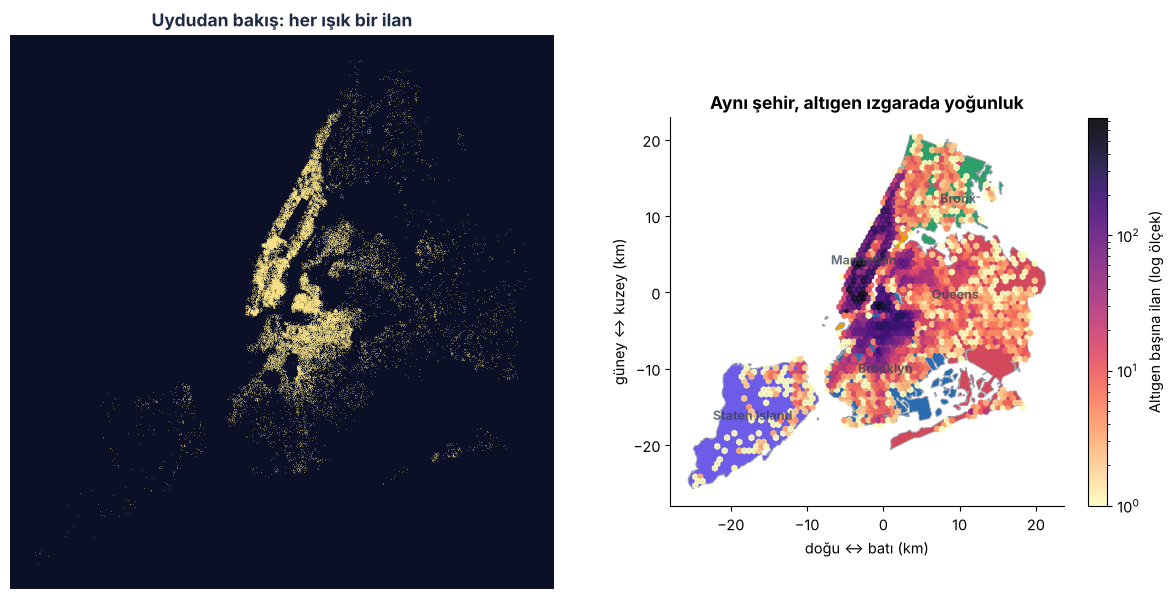

İlçelere göre ilan sayısı: {'Manhattan': np.int64(21661), 'Brooklyn': np.int64(20104), 'Queens': np.int64(5666), 'Bronx': np.int64(1091), 'Staten Island': np.int64(373)}


In [2]:
ilan = veri_oku()
PROJ = KmProjeksiyon().fit(ilan)                 # bu derste yalnızca çizim için; projede yalnızca eğitimle fit edilir
Z_tum = PROJ.transform(ilan)                      # [x_km, y_km]
print(f"İlan sayısı: {len(ilan):,}".replace(",", "."), "| Sütun sayısı:", ilan.shape[1])
display(ilan[["İlçe", "Mahalle", "Enlem", "Boylam", "Oda tipi", "Fiyat"]].head(5))

fig, ax = plt.subplots(1, 2, figsize=(15, 7.2), gridspec_kw={"width_ratios": [1.15, 1]})
gece_ekseni(ax[0])
ax[0].scatter(Z_tum[:, 0], Z_tum[:, 1], s=0.6, c="#FDE68A", alpha=.35, lw=0)
ax[0].set_title("Uydudan bakış: her ışık bir ilan", color=RENK["koyu"])
ax[0].set_aspect("equal")
nyc_haritasi(ax[1], PROJ, ilce_renk={k: v + "22" for k, v in ILCE_RENK.items()}, yazi=True)
hb = ax[1].hexbin(Z_tum[:, 0], Z_tum[:, 1], gridsize=70, bins="log", cmap="magma_r", mincnt=1, zorder=3, alpha=.9)
fig.colorbar(hb, ax=ax[1], shrink=.7, label="Altıgen başına ilan (log ölçek)")
ax[1].set(title="Aynı şehir, altıgen ızgarada yoğunluk", xlabel="doğu ↔ batı (km)", ylabel="güney ↔ kuzey (km)")
kaydet(fig, "kavram_01_sehrin_isiklari"); plt.show()

ilce = ilan["İlçe"].value_counts().reindex(ILCE_SIRA)
print("İlçelere göre ilan sayısı:", dict(ilce))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Haritada üç şey hemen göze çarpıyor:

1. **Yoğunluk eşit değil.** Manhattan ve kuzey Brooklyn göz kamaştırıcı bir halı gibi; Staten Island ve Bronx ise birkaç sönük ışıktan ibaret.
2. **Şekiller yuvarlak değil.** Işıklar nehir kıyıları, ana caddeler ve metro hatları boyunca **uzun, kıvrımlı** bantlar çiziyor.
3. **Yalnız ışıklar var.** Hiçbir kalabalığa ait olmayan tek tük ilanlar; bunları bir gruba zorla sokmak yanlış olurdu.

Bu üç özellik (farklı yoğunluk, serbest şekil, gürültü) bugünkü algoritmaların **neden var olduğunu** özetliyor.

</td></tr></table>

### 🌙 2.2 · K-Means'in Yuvarlak Dünyası

Dün (Gün 55–56) gördüğümüz K-Means her noktayı **en yakın merkeze** bağlar. Bu, kümeleri farkında olmadan **yuvarlak** ve **eşit büyüklükte** varsayar; üstelik her noktayı mutlaka bir kümeye koyar, "bu nokta kimseye ait değil" diyemez.

Yoğunluk tabanlı yöntemler başka bir soru sorar: **"Bu noktanın yanında yeterince komşu var mı?"** Varsa kalabalığın parçasıdır; kalabalıklar birbirine değiyorsa aynı kümedir; kimsenin yanında durmayan nokta **gürültüdür**.

<p align="center">
  <img src="assets/diyagram_sekil_tuzagi.svg" width="100%" alt="K-Means ve DBSCAN şekil karşılaştırması">
</p>

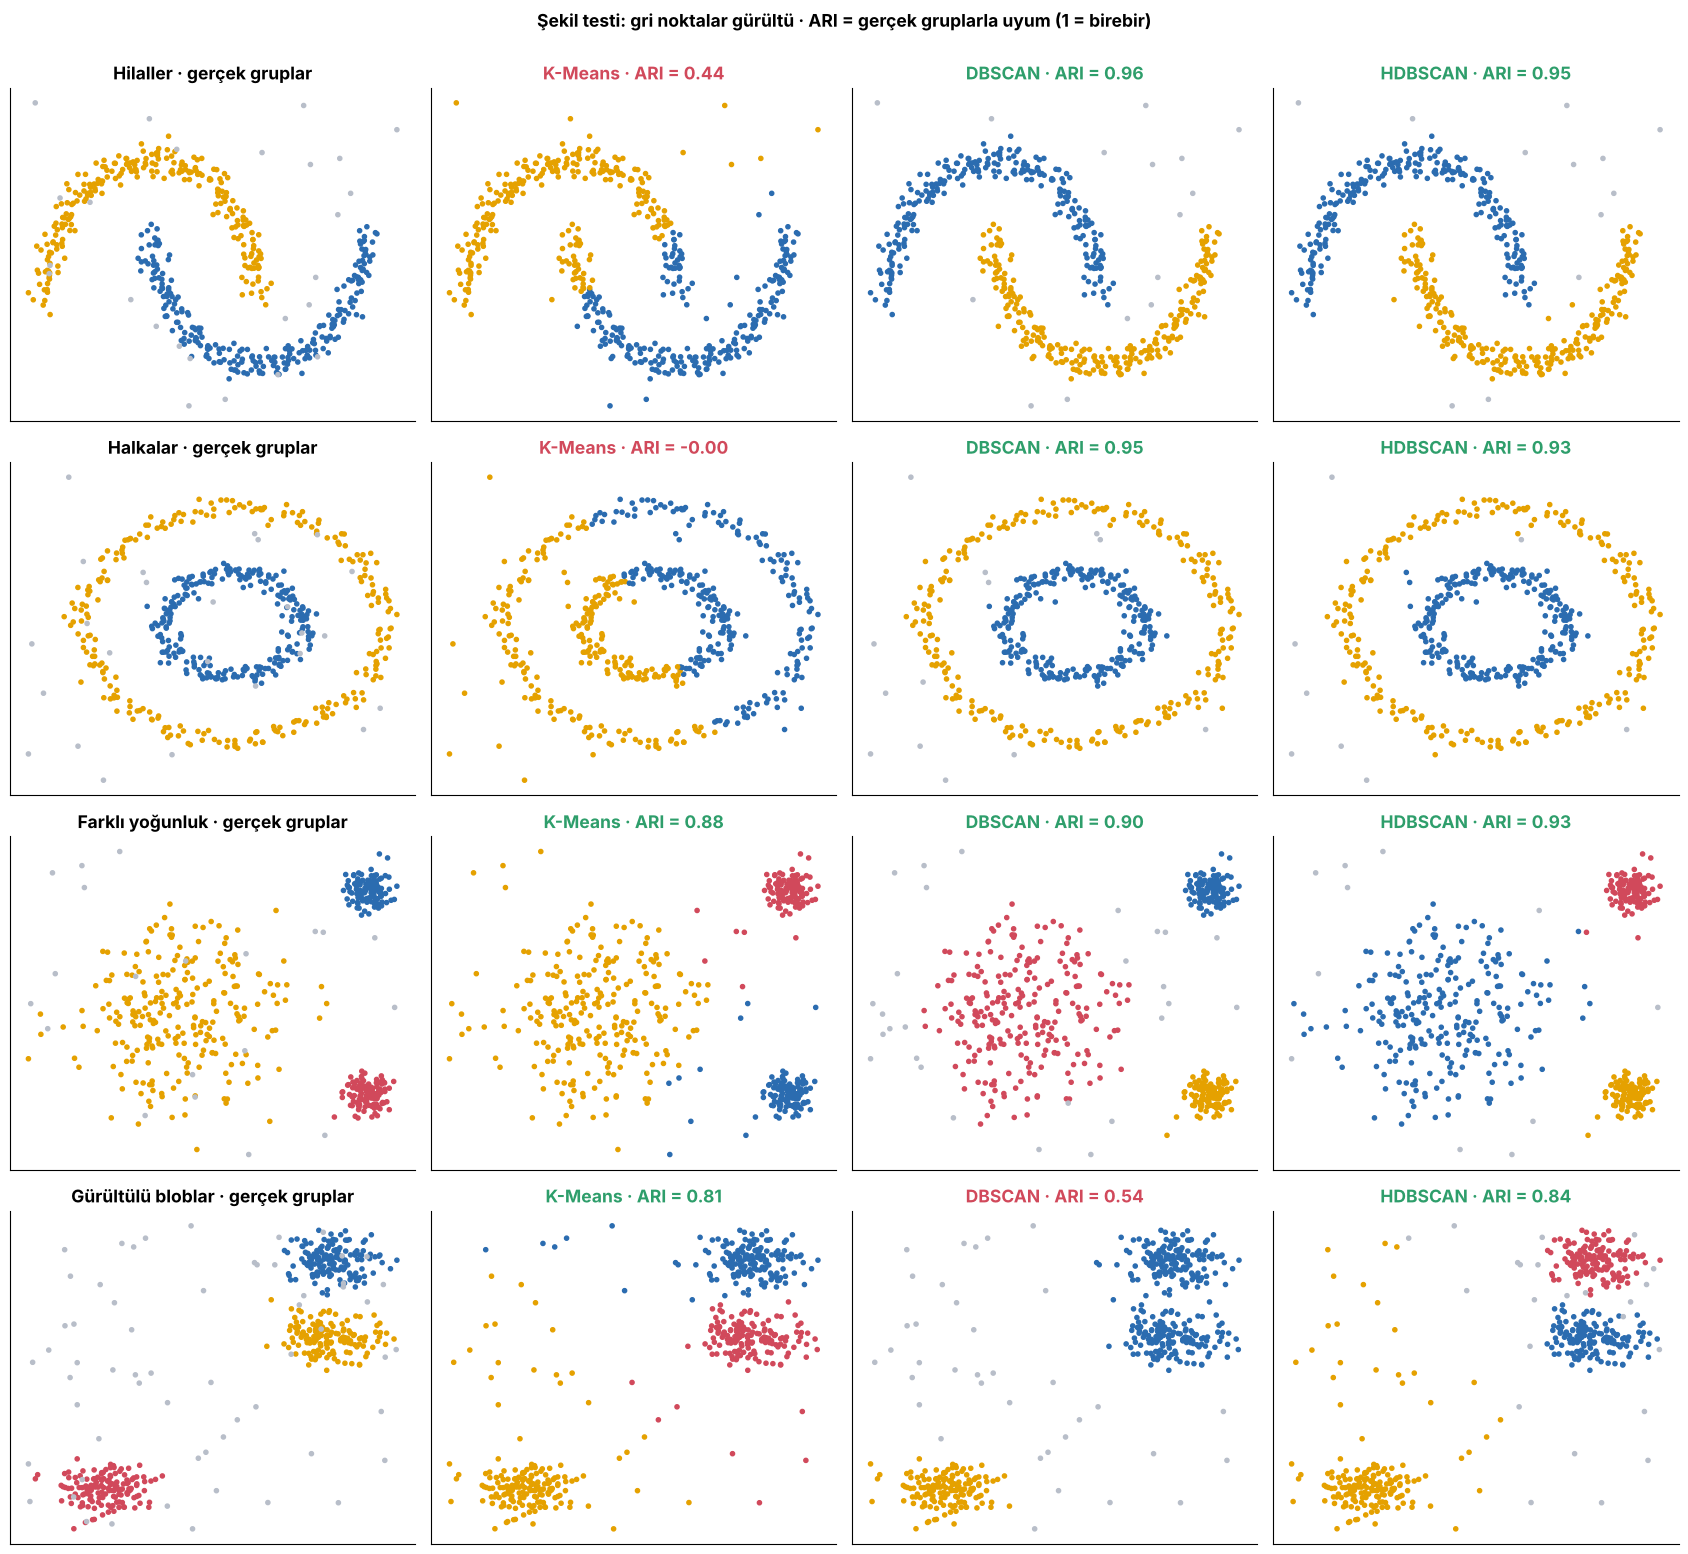

Yöntem,K-Means,DBSCAN,HDBSCAN
Veri,,,
Farklı yoğunluk,0.875,0.905,0.934
Gürültülü bloblar,0.810,0.537,0.842
Halkalar,-0.002,0.946,0.935
Hilaller,0.443,0.961,0.950


In [3]:
# Dört "zor" şekil: hilaller, iç içe halkalar, farklı yoğunluklar ve gürültülü bloblar
rng = np.random.default_rng(RANDOM_STATE)
def gurultu_ekle(X, y, n):
    G = rng.uniform(X.min(0) - .3, X.max(0) + .3, size=(n, 2))
    return np.r_[X, G], np.r_[y, -np.ones(n, int)]

veri_setleri = {
    "Hilaller": gurultu_ekle(*make_moons(500, noise=.06, random_state=1), 25),
    "Halkalar": gurultu_ekle(*make_circles(500, factor=.45, noise=.05, random_state=2), 25),
    "Farklı yoğunluk": gurultu_ekle(*make_blobs([250, 120, 120], centers=[[0, 0], [4, 3], [4, -2]], cluster_std=[1.1, .25, .25], random_state=3), 20),
    "Gürültülü bloblar": gurultu_ekle(*make_blobs(450, centers=3, cluster_std=.6, random_state=4), 60),
}
yontemler = {
    "K-Means": lambda X, k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X),
    "DBSCAN": lambda X, k: DBSCAN(eps=.25, min_samples=5).fit_predict(X),
    "HDBSCAN": lambda X, k: HDBSCAN(min_cluster_size=25, min_samples=5, copy=True).fit_predict(X),
}
satirlar = []
fig, ax = plt.subplots(4, 4, figsize=(17, 15.5))
for i, (ad, (X, y)) in enumerate(veri_setleri.items()):
    Xs = StandardScaler().fit_transform(X)
    k = len(set(y)) - (1 if -1 in y else 0)
    ax[i, 0].scatter(*Xs.T, c=renkler(y), s=9); ax[i, 0].set_title(f"{ad} · gerçek gruplar")
    for j, (y_ad, f) in enumerate(yontemler.items(), 1):
        et = f(Xs, k)
        ari = adjusted_rand_score(y, et)
        ax[i, j].scatter(*Xs.T, c=renkler(et), s=9)
        ax[i, j].set_title(f"{y_ad} · ARI = {ari:.2f}", color=RENK["yesil"] if ari > .8 else RENK["pembe"])
        satirlar.append({"Veri": ad, "Yöntem": y_ad, "ARI": round(ari, 3), "Küme": kume_ozeti(et)["Odak sayısı"],
                         "Gürültü %": round(kume_ozeti(et)["Gürültü %"], 1)})
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
fig.suptitle("Şekil testi: gri noktalar gürültü · ARI = gerçek gruplarla uyum (1 = birebir)", fontweight="bold", y=1.0)
fig.tight_layout(); kaydet(fig, "kavram_02_sekil_testi"); plt.show()
sekil = pd.DataFrame(satirlar).pivot(index="Veri", columns="Yöntem", values="ARI")[list(yontemler)]
sekil.to_csv(REP_DIR / "kavram_sekil_ari.csv"); display(sekil)

<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**ARI (Adjusted Rand Index)**, bulunan grupların gerçek gruplarla ne kadar örtüştüğünü ölçer: **1 = birebir aynı**, **0 = yazı-tura kadar**. Gerçek hayatta etiket olmadığı için ARI'yi yalnızca bu tür **oyuncak verilerde** ya da dış doğrulamada kullanabiliriz. Tabloda K-Means hilallerde ve halkalarda yanılıyor; yoğunluk yöntemleri şekli izliyor ve rastgele saçılmış noktaları **gri (gürültü)** bırakıyor. Dikkat: dört veri setinde de **aynı ayarı** (eps = 0,25, minPts = 5) kullandık. Bu ayar gürültülü bloblarda iki kalabalığı **birleştiriyor**: DBSCAN'in tek eps'i her veriye uymaz (6. ve 9. duraklar). HDBSCAN ise dört veride de tutarlı.

</td></tr></table>

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3: Fener ve kalabalık">
</p>

### 🔦 3.1 · İki Düğme: eps ve minPts

<table><tr><td>

<img src="assets/etiket_benzetme.svg" height="34" alt="Benzetme">

Karanlık bir meydanda herkesin elinde **aynı güçte bir fener** olduğunu düşünün.

- **eps** (epsilon) = fenerin **ışık yarıçapı**. "Yanımda" demek için kabul ettiğimiz en uzak mesafe.
- **minPts** (scikit-learn'de `min_samples`) = bir yerin **kalabalık** sayılması için fenerin aydınlatması gereken **en az kişi sayısı** (fener sahibi dahil).

</td></tr></table>

<p align="center">
  <img src="assets/diyagram_fener.svg" width="100%" alt="Fener benzetmesi: çekirdek, sınır ve gürültü">
</p>

### ⭐ 3.2 · Üç Nokta Türü

| Tür | Kural | Kümedeki rolü |
|:--|:--|:--|
| ⭐ **Çekirdek** (core) | Fenerinde **≥ minPts** kişi var | Kümeyi taşır, yayılmayı sağlar |
| 🔆 **Sınır** (border) | Kendi fenerinde az kişi var ama **bir çekirdeğin ışığında** | Kümeye katılır, ama yaymaz |
| ✖ **Gürültü** (noise) | **Hiçbir** çekirdeğin ışığında değil | Etiketi **−1** olur |

Aşağıda 34 noktalık küçük bir örnekte feneri her noktaya sırayla tutuyoruz (animasyon). Fenerin içine düşen kişi sayısını sayıp noktanın türüne karar veriyoruz.

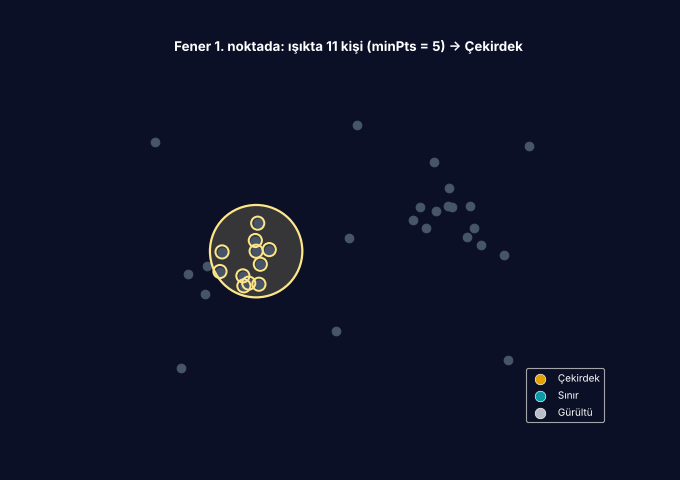

{'Çekirdek': 25, 'Gürültü': 7, 'Sınır': 2}


In [4]:
# 34 noktalık küçük bir meydan: iki kalabalık + birkaç yalnız
rng = np.random.default_rng(7)
M = np.r_[rng.normal([0, 0], .32, (14, 2)), rng.normal([2.3, .6], .28, (12, 2)),
          [[1.1, .25], [3.25, 1.35], [-1.2, 1.4], [3.0, -1.2], [-.9, -1.3], [1.2, 1.6], [.95, -.85], [2.95, .05]]]
EPS_M, MINPTS_M = .55, 5
db = DBSCAN(eps=EPS_M, min_samples=MINPTS_M).fit(M)
komsu_sayisi = (np.linalg.norm(M[:, None] - M[None], axis=2) <= EPS_M).sum(1)   # kendisi dahil
cekirdek = np.zeros(len(M), bool); cekirdek[db.core_sample_indices_] = True
tur = np.where(cekirdek, "Çekirdek", np.where(db.labels_ >= 0, "Sınır", "Gürültü"))
TUR_RENK = {"Çekirdek": RENK["altin"], "Sınır": RENK["cyan"], "Gürültü": GURULTU}

fig, ax = plt.subplots(figsize=(8.5, 6))
def ciz(i):
    ax.clear(); gece_ekseni(ax); ax.set_aspect("equal"); ax.set_xlim(-2, 4.2); ax.set_ylim(-2, 2.4)
    bilinen = tur[:i]
    ax.scatter(*M[i:].T, s=60, c="#475569", zorder=2)
    for t in TUR_RENK:
        m = bilinen == t
        ax.scatter(*M[:i][m].T, s=90, c=TUR_RENK[t], zorder=3, edgecolor="white", lw=.6, label=t)
    if i < len(M):
        p = M[i]; icerde = np.linalg.norm(M - p, axis=1) <= EPS_M
        ax.add_patch(plt.Circle(p, EPS_M, color="#FDE68A", alpha=.18, zorder=1))
        ax.add_patch(plt.Circle(p, EPS_M, fill=False, color="#FDE68A", lw=2, zorder=4))
        ax.scatter(*M[icerde].T, s=140, facecolor="none", edgecolor="#FDE68A", lw=1.8, zorder=5)
        ax.set_title(f"Fener {i+1}. noktada: ışıkta {komsu_sayisi[i]} kişi (minPts = {MINPTS_M}) → {tur[i]}",
                     color="white", fontsize=12)
    else:
        ax.set_title("Tüm noktalar sınıflandı: ⭐ çekirdek · 🔆 sınır · ✖ gürültü", color="white", fontsize=12)
    ax.legend(loc="lower right", facecolor=RENK["gece"], labelcolor="white", fontsize=9)
    fig.patch.set_facecolor(RENK["gece"])
anim = FuncAnimation(fig, ciz, frames=list(range(len(M) + 1)) + [len(M)] * 4)
gif_kaydet(anim, "kavram_03_fener_tarama", fps=3)
print(pd.Series(tur).value_counts().to_dict())

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Sınır noktaları "kalabalığın kenarında duranlar"dır: kendi fenerlerinde yeterince kişi yoktur ama bir çekirdeğin ışığı onlara ulaşır. Gri noktaların fenerinde yalnızca birkaç kişi vardır **ve** hiçbir çekirdek onlara ışık tutmaz; DBSCAN onları **−1** ile işaretler.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4: Canlı DBSCAN">
</p>

### 🔥 4.1 · Bir Kıvılcım, Bir Yangın

DBSCAN'i bir **orman yangını** gibi düşünebiliriz: bir çekirdek noktada kıvılcım çıkar; ateş, ışığı içindeki herkese sıçrar. Sıçradığı kişi de çekirdekse ateş onun ışığından **yayılmaya devam eder**; sınır noktasında ise alev alır ama **durur**. Yangın sönünce henüz yanmamış yeni bir çekirdek aranır ve **yeni renkte** bir yangın başlar.

<p align="center">
  <img src="assets/diyagram_dbscan_adimlari.svg" width="100%" alt="DBSCAN beş adım">
</p>

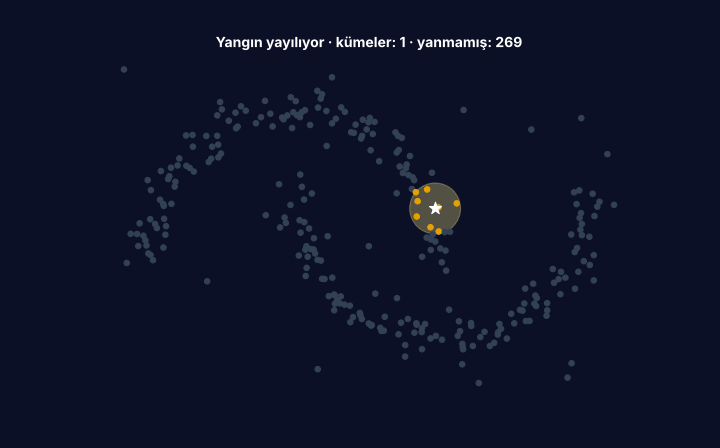

In [5]:
# DBSCAN'i elle (genişlik öncelikli arama) yazıp her adımı kaydediyoruz
X_h, y_h = make_moons(260, noise=.07, random_state=3)
X_h = np.r_[X_h, np.random.default_rng(5).uniform([-1.3, -.8], [2.3, 1.3], (18, 2))]
EPS_H, MIN_H = .17, 5

def adim_adim_dbscan(X, eps, min_pts):
    komsu = NearestNeighbors(radius=eps).fit(X).radius_neighbors(X, return_distance=False)
    cekirdek = np.array([len(k) >= min_pts for k in komsu])
    et = np.full(len(X), -1); kume = -1; kareler = []
    for p in range(len(X)):
        if et[p] != -1 or not cekirdek[p]:
            continue
        kume += 1; et[p] = kume; kuyruk = [p]
        while kuyruk:
            q = kuyruk.pop(0)
            if not cekirdek[q]:
                continue                                    # sınır: alev alır ama yaymaz
            yeni = [r for r in komsu[q] if et[r] == -1]
            et[yeni] = kume; kuyruk += yeni
            if yeni:
                kareler.append((et.copy(), q))
    return et, cekirdek, kareler

et_elle, cek_elle, kareler = adim_adim_dbscan(X_h, EPS_H, MIN_H)
secim = kareler[::max(1, len(kareler) // 45)] + [(et_elle, None)] * 6
fig, ax = plt.subplots(figsize=(9, 5.6))
def ciz(i):
    et, q = secim[i]
    ax.clear(); gece_ekseni(ax); fig.patch.set_facecolor(RENK["gece"])
    ax.scatter(*X_h.T, s=24, c=[("#334155" if e < 0 else KUME_RENK[e]) for e in et], zorder=2)
    if q is not None:
        ax.add_patch(plt.Circle(X_h[q], EPS_H, color="#FDE68A", alpha=.3, zorder=1))
        ax.scatter(*X_h[q], s=130, marker="*", c="white", zorder=3)
        ax.set_title(f"Yangın yayılıyor · kümeler: {et.max()+1} · yanmamış: {(et < 0).sum()}", color="white")
    else:
        ax.scatter(*X_h[et < 0].T, s=34, marker="x", c=GURULTU, zorder=3)
        ax.set_title(f"Yangın söndü: {et.max()+1} küme · {(et < 0).sum()} gürültü (×)", color="white")
    ax.set_aspect("equal")
anim = FuncAnimation(fig, ciz, frames=len(secim))
gif_kaydet(anim, "kavram_04_canli_dbscan", fps=6)

### ✅ 4.2 · Elle Yazdığımız DBSCAN, scikit-learn ile Aynı mı?

Kendi yazdığımız 15 satırlık sürüm ile `sklearn.cluster.DBSCAN`'i aynı veri ve aynı düğmelerle çalıştırıp karşılaştıralım. Küme numaraları farklı sırada olabilir; bu yüzden **ARI** ile bakıyoruz (1 = birebir aynı gruplama).

In [6]:
et_sk = DBSCAN(eps=EPS_H, min_samples=MIN_H).fit_predict(X_h)
print("Elle küme sayısı:", et_elle.max() + 1, "| scikit-learn:", et_sk.max() + 1)
print("Gürültü (elle / sklearn):", (et_elle < 0).sum(), "/", (et_sk < 0).sum())
print("ARI(elle, sklearn) =", round(adjusted_rand_score(et_elle, et_sk), 4))

Elle küme sayısı: 2 | scikit-learn: 2
Gürültü (elle / sklearn): 10 / 10
ARI(elle, sklearn) = 1.0


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

İki sürüm **aynı** kümeleri ve **aynı** gürültüyü buluyor. DBSCAN'in bütün sırrı bu kadar: *komşuları say → çekirdekleri bul → çekirdekten çekirdeğe yay*. Kaç küme olacağını **siz söylemediniz**; yangınların sayısı verinin şeklinden çıktı.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5: Elle DBSCAN">
</p>

### ✍️ 5.1 · Bir Sokakta 12 İlan

Brooklyn'de kısa bir sokak düşünelim. 12 ilanın konumunu **metre** cinsinden yazdık (sokağın başı = 0). Fener yarıçapı **eps = 150 m**, kalabalık eşiği **minPts = 3** (kendisi dahil).

Elle yapacağımız iş üç adım:

1. Her ilan için **150 m içindeki ilanları** say.
2. Sayı ≥ 3 ise **çekirdek**; değilse bir çekirdeğin 150 m'sindeyse **sınır**; hiçbiri değilse **gürültü**.
3. Birbirinin 150 m'sindeki çekirdekleri **aynı kümeye** bağla.

In [7]:
sokak = pd.DataFrame({"İlan": list("ABCDEFGHIJKL"),
                      "x (m)": [0, 60, 110, 170, 300, 520, 600, 640, 700, 830, 1050, 1350],
                      "y (m)": [0, 40, -30, 10, 60, 0, 60, -40, 20, -10, 300, -80]})
P = sokak[["x (m)", "y (m)"]].to_numpy(float)
D = np.sqrt(((P[:, None] - P[None]) ** 2).sum(-1))
EPS, MINPTS = 150, 3
mesafe = pd.DataFrame(D.round(0).astype(int), index=sokak["İlan"], columns=sokak["İlan"])
display(mesafe.style.background_gradient(cmap="YlOrBr_r", vmin=0, vmax=400)
        .map(lambda v: "font-weight:bold; color:#14532D" if v <= EPS else "color:#9CA3AF")
        .set_caption("İlanlar arası mesafe (m) · kalın yeşil: 150 m içinde"))

sokak["150 m içinde (kendisi dahil)"] = (D <= EPS).sum(1)
sokak["Çekirdek mi?"] = sokak["150 m içinde (kendisi dahil)"] >= MINPTS
cek = sokak["Çekirdek mi?"].to_numpy()
cekirdege_yakin = ((D <= EPS) & cek[None, :]).any(1)
sokak["Tür"] = np.where(cek, "⭐ Çekirdek", np.where(cekirdege_yakin, "🔆 Sınır", "✖ Gürültü"))
display(sokak)

İlan,A,B,C,D,E,F,G,H,I,J,K,L
İlan,,,,,,,,,,,,
A,0,72,114,170,306,520,603,641,700,830,1092,1352
B,72,0,86,114,241,462,540,585,640,772,1024,1296
C,114,86,0,72,210,411,498,530,592,720,996,1241
D,170,114,72,0,139,350,433,473,530,660,927,1183
E,306,241,210,139,0,228,300,354,402,535,787,1059
F,520,462,411,350,228,0,100,126,181,310,609,834
G,603,540,498,433,300,100,0,108,108,240,510,763
H,641,585,530,473,354,126,108,0,85,192,533,711
I,700,640,592,530,402,181,108,85,0,133,448,658


,İlan,x (m),y (m),150 m içinde (kendisi dahil),Çekirdek mi?,Tür
0,A,0,0,3,True,⭐ Çekirdek
1,B,60,40,4,True,⭐ Çekirdek
2,C,110,-30,4,True,⭐ Çekirdek
3,D,170,10,4,True,⭐ Çekirdek
4,E,300,60,2,False,🔆 Sınır
5,F,520,0,3,True,⭐ Çekirdek
6,G,600,60,4,True,⭐ Çekirdek
7,H,640,-40,4,True,⭐ Çekirdek
8,I,700,20,4,True,⭐ Çekirdek
9,J,830,-10,2,False,🔆 Sınır


İlan,A,B,C,D,E,F,G,H,I,J,K,L
Tür,⭐ Çekirdek,⭐ Çekirdek,⭐ Çekirdek,⭐ Çekirdek,🔆 Sınır,⭐ Çekirdek,⭐ Çekirdek,⭐ Çekirdek,⭐ Çekirdek,🔆 Sınır,✖ Gürültü,✖ Gürültü
Elle küme,0,0,0,0,0,1,1,1,1,1,-1,-1
scikit-learn,0,0,0,0,0,1,1,1,1,1,-1,-1


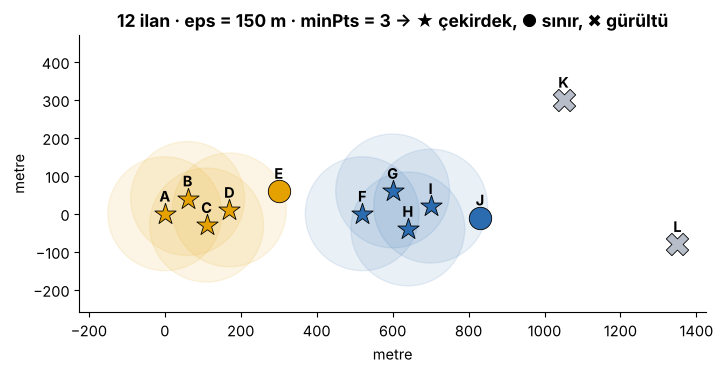

In [8]:
# Adım 3: çekirdekleri birbirine bağla (150 m içindeki çekirdekler aynı küme)
from scipy.sparse.csgraph import connected_components
bag = (D <= EPS) & cek[:, None] & cek[None, :]
_, bilesen = connected_components(bag[np.ix_(cek, cek)], directed=False)
elle = np.full(len(P), -1); elle[cek] = bilesen
for i in np.where(~cek & cekirdege_yakin)[0]:                 # sınır → en yakın çekirdeğin kümesi
    j = np.where(cek)[0][np.argmin(D[i, cek])]; elle[i] = elle[j]
sokak["Elle küme"] = elle
sokak["scikit-learn"] = DBSCAN(eps=EPS, min_samples=MINPTS).fit_predict(P)
display(sokak[["İlan", "Tür", "Elle küme", "scikit-learn"]].set_index("İlan").T)

fig, ax = plt.subplots(figsize=(14, 3.6))
for i, r in sokak.iterrows():
    renk = GURULTU if r["Elle küme"] < 0 else KUME_RENK[r["Elle küme"]]
    if r["Çekirdek mi?"]:
        ax.add_patch(plt.Circle(P[i], EPS, color=renk, alpha=.10))
    ax.scatter(*P[i], s=260, c=renk, marker="*" if r["Çekirdek mi?"] else ("o" if r["Elle küme"] >= 0 else "X"),
               edgecolor="k", lw=.6, zorder=3)
    ax.annotate(r["İlan"], P[i] + [0, 32], ha="center", fontweight="bold")
ax.set_aspect("equal"); ax.set(xlabel="metre", ylabel="metre", ylim=(-260, 470),
                               title="12 ilan · eps = 150 m · minPts = 3 → ★ çekirdek, ● sınır, ✖ gürültü")
kaydet(fig, "kavram_05_elle_dbscan"); plt.show()

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Elle bulduğumuz kümeler scikit-learn ile **aynı**: sokağın başında bir kalabalık (A–E), ortasında ikinci bir kalabalık (F–J) ve sokağın sonunda **kimsenin yanında olmayan** iki ilan (K, L). **E** ve **J** sınır noktası: 150 m içinde yalnızca bir komşuları var (kendileriyle 2 < 3), ama o komşu bir çekirdek olduğu için kümeye katılıyorlar. K-Means'e "k = 2" deseydik K ve L'yi de zorla bir gruba sokacaktı; DBSCAN onları **dürüstçe dışarıda** bıraktı.

</td></tr></table>

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6: eps düğmesi">
</p>

### 🎚️ 6.1 · Feneri Büyütüp Küçültmek

<p align="center">
  <img src="assets/diyagram_eps_dugmesi.svg" width="100%" alt="eps düğmesi">
</p>

Şimdi gerçek veriye dönelim. Kuzey Brooklyn ve Aşağı Manhattan'dan **4.000 ilanlık** bir pencere alıp minPts = 15 sabitken eps'i **30 metreden 600 metreye** büyütüyoruz.

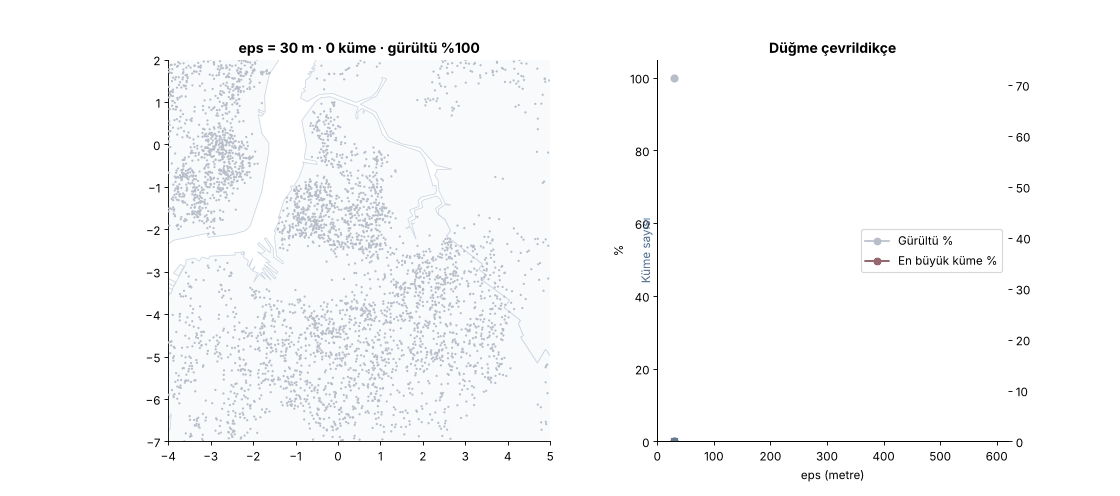

,eps (m),Odak sayısı,Gürültü %,En büyük odak %
0,30,0.0,100.0,0.0
2,50,0.0,100.0,0.0
3,70,0.0,100.0,0.0
4,90,4.0,98.0,0.6
5,110,8.0,91.7,2.9
6,130,24.0,77.4,4.4
7,160,21.0,56.9,13.2
8,200,30.0,31.3,17.1
9,250,12.0,13.1,37.0
10,300,3.0,8.2,67.5


In [9]:
# Pencere: Aşağı Manhattan + Kuzey Brooklyn (yaklaşık 9 km × 9 km)
pencere = (Z_tum[:, 0] > -4) & (Z_tum[:, 0] < 5) & (Z_tum[:, 1] > -7) & (Z_tum[:, 1] < 2)
idx = np.random.default_rng(RANDOM_STATE).choice(np.where(pencere)[0], 4000, replace=False)
Zp = Z_tum[idx]
EPS_LISTE = [.03, .05, .07, .09, .11, .13, .16, .2, .25, .3, .4, .5, .6]
eps_satir = []
fig, ax = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
a2 = ax[1].twinx()
def ciz(i):
    eps = EPS_LISTE[min(i, len(EPS_LISTE) - 1)]
    et = DBSCAN(eps=eps, min_samples=15).fit_predict(Zp); oz = kume_ozeti(et)
    if len(eps_satir) < len(EPS_LISTE) and i < len(EPS_LISTE):
        eps_satir.append({"eps (m)": int(eps * 1000), **{k: round(float(v), 1) for k, v in oz.items()}})
    for a in ax: a.clear()
    nyc_haritasi(ax[0], PROJ, dolgu="#F8FAFC", kenar="#CBD5E1")
    ax[0].scatter(*Zp.T, s=4, c=renkler(et), lw=0, zorder=3)
    ax[0].set_xlim(-4, 5); ax[0].set_ylim(-7, 2)
    ax[0].set_title(f"eps = {eps*1000:.0f} m · {oz['Odak sayısı']} küme · gürültü %{oz['Gürültü %']:.0f}")
    t = pd.DataFrame(eps_satir)
    ax[1].plot(t["eps (m)"], t["Gürültü %"], "o-", c=GURULTU, label="Gürültü %")
    ax[1].plot(t["eps (m)"], t["En büyük odak %"], "o-", c=RENK["pembe"], label="En büyük küme %")
    a2.clear()
    a2.plot(t["eps (m)"], t["Odak sayısı"], "s--", c=RENK["mavi"], label="Küme sayısı")
    a2.set_ylabel("Küme sayısı", color=RENK["mavi"]); a2.set_ylim(0, 75)
    ax[1].set(xlim=(0, 620), ylim=(0, 105), xlabel="eps (metre)", ylabel="%", title="Düğme çevrildikçe")
    ax[1].legend(loc="center right")
anim = FuncAnimation(fig, ciz, frames=len(EPS_LISTE) + 4)
gif_kaydet(anim, "kavram_06_eps_supurme", fps=2)
eps_tablo = pd.DataFrame(eps_satir).drop_duplicates("eps (m)")
eps_tablo.to_csv(REP_DIR / "kavram_eps_supurme.csv", index=False); display(eps_tablo)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

- **eps çok küçükken** (30–50 m) feneri kimseye yetmiyor: neredeyse herkes **gürültü**.
- **eps büyüdükçe** küme sayısı önce **artıyor** (kalabalıklar ortaya çıkıyor), sonra **azalıyor** (kalabalıklar birbirine değip **birleşiyor**).
- **eps çok büyükken** neredeyse tüm pencere **tek bir dev küme**: Manhattan ile Brooklyn arasındaki nehir bile onları ayıramıyor.

"Doğru" eps tek bir sayı değil, bir **aralıktır**; o aralığı bulmak için 7. duraktaki k-mesafe grafiğini kullanacağız.

</td></tr></table>

### 👥 6.2 · minPts: Kalabalık Eşiği

minPts'i büyütmek "kalabalık" tanımını **sıkılaştırır**: daha az nokta çekirdek olur, gürültü artar, küçük kümeler kaybolur. Pratik bir başlangıç kuralı **minPts ≥ boyut + 1** (iki boyutta en az 3); gürültülü ve büyük veride genellikle **2 × boyut** ya da daha fazlası seçilir (Sander ve ark., 1998; Schubert ve ark., 2017'den aktarma).

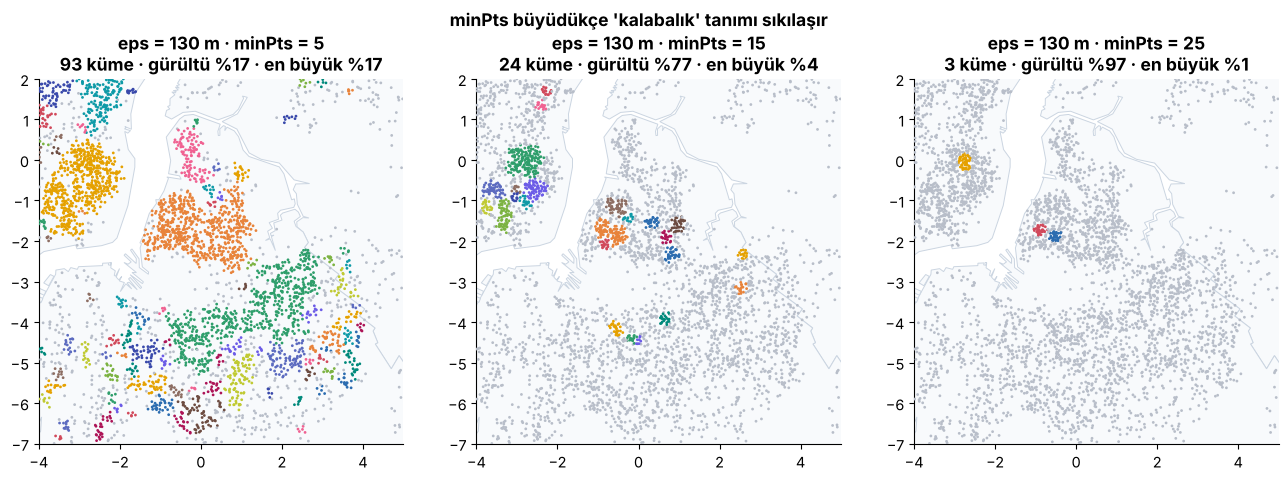

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
for a, mp in zip(ax, [5, 15, 25]):
    et = DBSCAN(eps=.13, min_samples=mp).fit_predict(Zp); oz = kume_ozeti(et)
    nyc_haritasi(a, PROJ, dolgu="#F8FAFC", kenar="#CBD5E1")
    a.scatter(*Zp.T, s=4, c=renkler(et), lw=0, zorder=3); a.set_xlim(-4, 5); a.set_ylim(-7, 2)
    a.set_title(f"eps = 130 m · minPts = {mp}\n{oz['Odak sayısı']} küme · gürültü %{oz['Gürültü %']:.0f} · en büyük %{oz['En büyük odak %']:.0f}")
fig.suptitle("minPts büyüdükçe 'kalabalık' tanımı sıkılaşır", fontweight="bold")
kaydet(fig, "kavram_07_minpts"); plt.show()

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7: k-mesafe grafiği">
</p>

### 📈 7.1 · eps'i Veriye Sormak

<p align="center">
  <img src="assets/diyagram_k_mesafe.svg" width="100%" alt="k-mesafe grafiği">
</p>

Tarif basit (Ester ve ark., 1996; Schubert ve ark., 2017'den aktarma):

1. Her nokta için **k'ıncı en yakın komşusuna** olan mesafeyi bul (k = minPts − 1 ya da minPts).
2. Bu mesafeleri **küçükten büyüğe sırala** ve çiz.
3. Eğrinin **düzden dike döndüğü** yer (dirsek, *knee*) eps için iyi bir adaydır.

Dirseği gözle aramak yerine `kneed` kütüphanesinin **Kneedle** algoritmasını kullanıyoruz (Satopää ve ark., 2011).

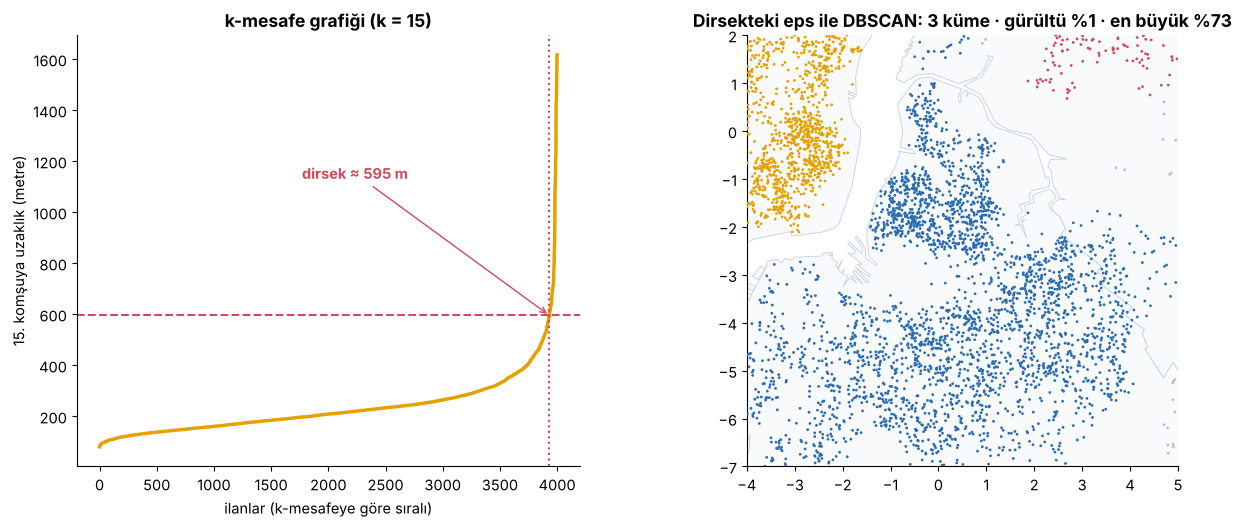

In [11]:
K = 15
k_uzak = np.sort(NearestNeighbors(n_neighbors=K).fit(Zp).kneighbors(Zp)[0][:, -1])
diz = KneeLocator(np.arange(len(k_uzak)), k_uzak, curve="convex", direction="increasing")
eps_diz = float(k_uzak[diz.knee])
et_diz = DBSCAN(eps=eps_diz, min_samples=K).fit_predict(Zp); oz = kume_ozeti(et_diz)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].plot(k_uzak * 1000, c=RENK["altin"], lw=2.5)
ax[0].axhline(eps_diz * 1000, ls="--", c=RENK["pembe"]); ax[0].axvline(diz.knee, ls=":", c=RENK["pembe"])
ax[0].annotate(f"dirsek ≈ {eps_diz*1000:.0f} m", (diz.knee, eps_diz * 1000), xytext=(diz.knee * .45, eps_diz * 1000 * 1.9),
               arrowprops=dict(arrowstyle="->", color=RENK["pembe"]), color=RENK["pembe"], fontweight="bold")
ax[0].set(xlabel="ilanlar (k-mesafeye göre sıralı)", ylabel=f"{K}. komşuya uzaklık (metre)",
          title=f"k-mesafe grafiği (k = {K})")
nyc_haritasi(ax[1], PROJ, dolgu="#F8FAFC", kenar="#CBD5E1")
ax[1].scatter(*Zp.T, s=4, c=renkler(et_diz), lw=0, zorder=3); ax[1].set_xlim(-4, 5); ax[1].set_ylim(-7, 2)
ax[1].set_title(f"Dirsekteki eps ile DBSCAN: {oz['Odak sayısı']} küme · gürültü %{oz['Gürültü %']:.0f} · en büyük %{oz['En büyük odak %']:.0f}")
kaydet(fig, "kavram_08_k_mesafe"); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Dirsek **bir başlangıç noktasıdır, kural değildir.** Şehir verisinde dirsek genellikle "kalabalığın içi" ile "ıssız uçlar" arasındaki sınırı yakalar; bu da çoğu zaman **büyük ve birbirine değen** kümeler verir. Manhattan gibi kesintisiz bir halıda "kalabalığın içindeki daha kalabalık yerleri" bulmak istiyorsak daha küçük bir eps ya da **farklı yoğunlukları aynı anda tarayan** bir yöntem (9. durak: HDBSCAN) gerekir. Proje notebook'unda eps'i bu yüzden bir **parametre haritası** üzerinden seçeceğiz.

</td></tr></table>

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8: Birim meselesi">
</p>

### 📏 8.1 · eps = 0,003 Ne Demek?

<p align="center">
  <img src="assets/diyagram_birim.svg" width="100%" alt="Birim meselesi">
</p>

Referans çalışmalarda konum verisi çoğu zaman **standartlaştırılır** (z-skor). Bu, birimleri farklı özellikleri (ör. gelir ve yaş) aynı terazide tartmak için doğrudur. Ama iki eksen de **aynı fiziksel birimdeyse** (metre), standartlaştırma şehrin en-boy oranını bozar. Derece kullanmak da tuzaktır: New York'ta **1° boylam ≈ 84 km**, **1° enlem ≈ 111 km**. Yani dereceyle çizilen "daire" aslında yatay basık bir **elips**tir.

New York'ta 1° boylam ≈ 84.4 km · 1° enlem ≈ 110.6 km


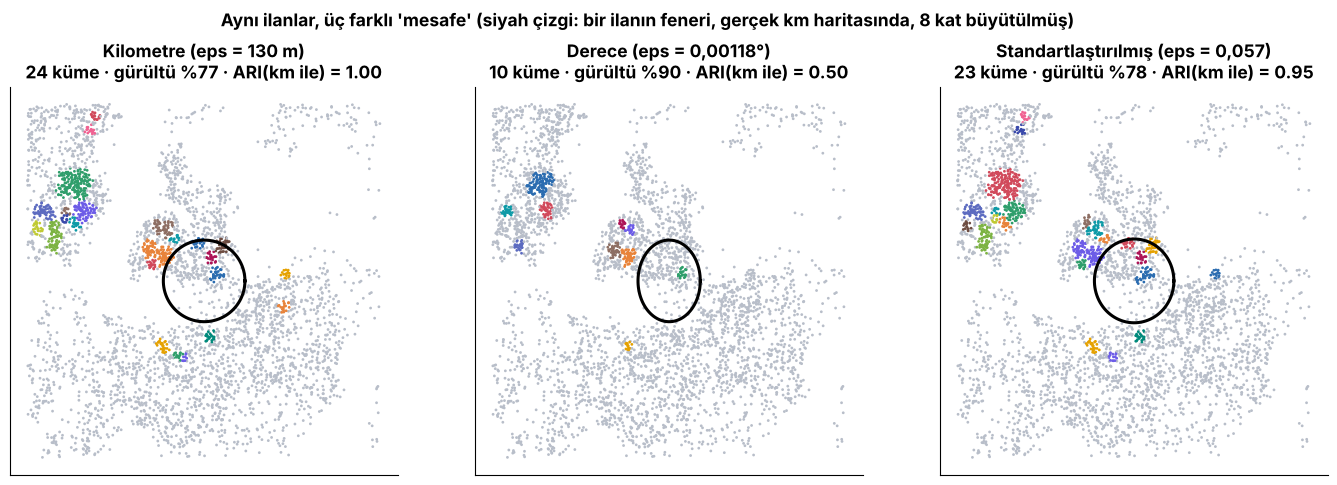

,Uzay,Odak sayısı,Gürültü %,En büyük odak %,ARI (km'ye göre)
0,Kilometre (eps = 130 m),24.0,77.4,4.4,1.000
1,"Derece (eps = 0,00118°)",10.0,90.3,2.9,0.499
2,"Standartlaştırılmış (eps = 0,057)",23.0,78.2,4.3,0.949


In [12]:
LL = ilan.loc[idx, ["Enlem", "Boylam"]].to_numpy()
km_boylam = PROJ.km_boylam_
print(f"New York'ta 1° boylam ≈ {km_boylam:.1f} km · 1° enlem ≈ 110.6 km")

EPS_KM = .13
z_olcek = StandardScaler().fit(Zp).scale_
eps_der, eps_z = EPS_KM / 110.574, EPS_KM / z_olcek.mean()       # kuzey-güneyde 130 m'ye / ortalama ölçekte 130 m'ye denk
uzaylar = {
    "Kilometre (eps = 130 m)": (Zp, EPS_KM),
    f"Derece (eps = {eps_der:.5f}°)".replace(".", ","): (LL[:, ::-1], eps_der),
    f"Standartlaştırılmış (eps = {eps_z:.3f})".replace(".", ","): (StandardScaler().fit_transform(Zp), eps_z),
}
fig, ax = plt.subplots(1, 3, figsize=(17, 5.6)); birim_satir = []
ref = DBSCAN(eps=EPS_KM, min_samples=15).fit_predict(Zp)
for a, (ad, (U, e)) in zip(ax, uzaylar.items()):
    et = DBSCAN(eps=e, min_samples=15).fit_predict(U); oz = kume_ozeti(et)
    a.scatter(*Zp.T, s=4, c=renkler(et), lw=0); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    # Merkezdeki bir ilan için "fener" bu uzayda gerçek kilometre haritasında neye benziyor?
    rx, ry = {"K": (e, e), "D": (e * km_boylam, e * 110.574), "S": (e * z_olcek[0], e * z_olcek[1])}[ad[0]]
    rx, ry = 8 * rx, 8 * ry                                                     # görünür olsun diye 8 kat büyütülmüş
    t = np.linspace(0, 2 * np.pi, 100)
    a.plot(.5 + float(rx) * np.cos(t), -2.5 + float(ry) * np.sin(t), c="k", lw=2.2)          # fener (km haritasında)
    a.set_title(f"{ad}\n{oz['Odak sayısı']} küme · gürültü %{oz['Gürültü %']:.0f} · ARI(km ile) = {adjusted_rand_score(ref, et):.2f}")
    birim_satir.append({"Uzay": ad, **{k: round(float(v), 1) for k, v in oz.items()}, "ARI (km'ye göre)": round(adjusted_rand_score(ref, et), 3)})
fig.suptitle("Aynı ilanlar, üç farklı 'mesafe' (siyah çizgi: bir ilanın feneri, gerçek km haritasında, 8 kat büyütülmüş)", fontweight="bold")
kaydet(fig, "kavram_09_birim"); plt.show()
pd.DataFrame(birim_satir).to_csv(REP_DIR / "kavram_birim.csv", index=False); display(pd.DataFrame(birim_satir))

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Siyah çizgi, aynı eps'in **gerçek kilometre haritasında** hangi bölgeyi kapsadığını gösteriyor. Derece ve z-skor uzaylarında fener **daire değil elips**: doğu-batı ile kuzey-güney yönleri eşit davranmıyor. Kilometre ızgarasında ise eps'in bir **fiziksel anlamı** var ("130 metre içindeki ilanlar"); bu, sonuçları belediye yetkilisine anlatırken de büyük kolaylık.

Çok büyük alanlarda (ülke, kıta) dünyanın eğriliği önemli hale gelir; o zaman `metric="haversine"` ile radyan cinsinden çalışmak gerekir. Şehir ölçeğinde (~50 km) bizim düz ızgaramız metre düzeyinde doğrudur.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9: Farklı yoğunluklar">
</p>

### 🏝️ 9.1 · DBSCAN'in Zaafı: Tek Bir eps Herkese Uymaz

DBSCAN'in bütün kümeler için **tek ve sabit** bir yoğunluk eşiği vardır. Bir şehirde hem Manhattan gibi göz kamaştırıcı hem de Staten Island gibi sönük bölgeler varsa ne olur? Küçük eps seyrek bölgeyi **gürültü** sayar; büyük eps yoğun bölgedeki ayrı kalabalıkları **birleştirir**.

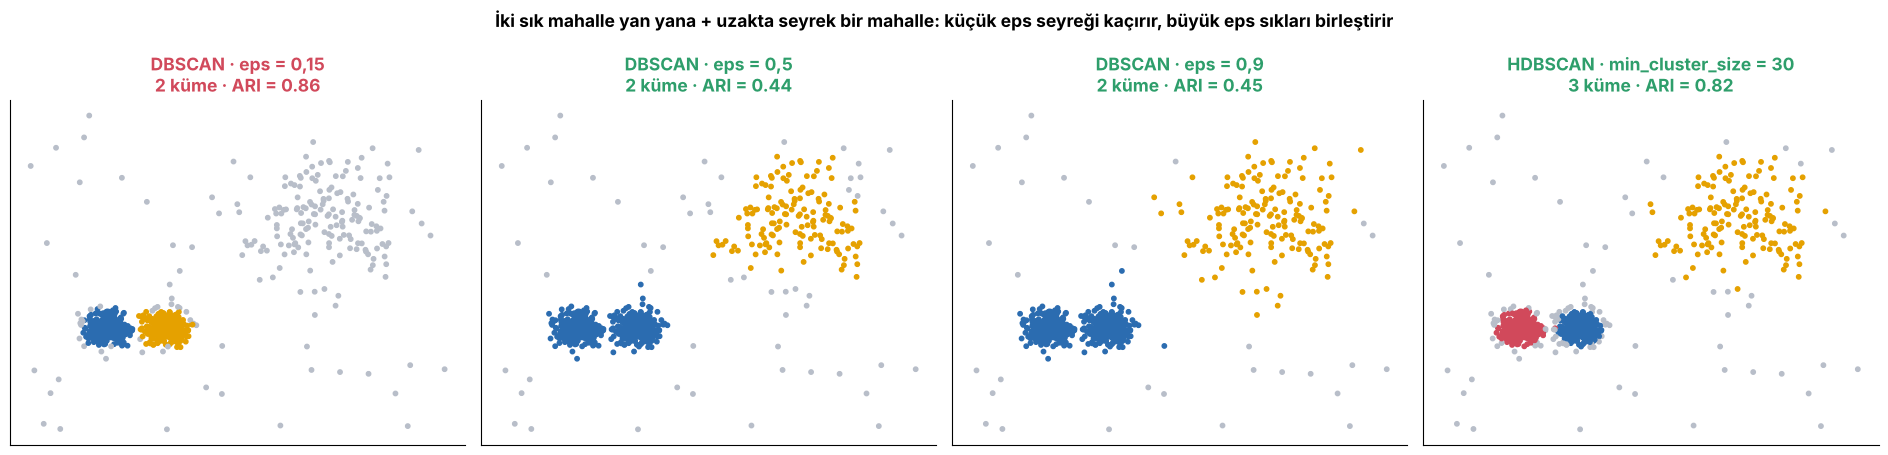

,Yöntem,Küme,Gürültü %,Seyrek mahalle bulundu %,Sık ikizler birleşti mi?,ARI
0,"DBSCAN · eps = 0,15",2,28.1,0.0,hayır,0.859
1,"DBSCAN · eps = 0,5",2,6.9,86.9,evet,0.440
2,"DBSCAN · eps = 0,9",2,3.9,98.8,evet,0.452
3,HDBSCAN · min_cluster_size = 30,3,13.6,91.9,hayır,0.818


In [13]:
# Üç farklı yoğunlukta "mahalle" + seyrek gürültü
X_y, y_y = make_blobs([300, 300, 160], centers=[[0, 0], [1.4, 0], [5, 3]], cluster_std=[.25, .25, .9], random_state=11)
X_y = np.r_[X_y, np.random.default_rng(11).uniform([-2, -3], [8, 6], (40, 2))]; y_y = np.r_[y_y, -np.ones(40, int)]
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6)); fy = []
ayarlar = [("DBSCAN · eps = 0,15", DBSCAN(eps=.15, min_samples=8)), ("DBSCAN · eps = 0,5", DBSCAN(eps=.5, min_samples=8)),
           ("DBSCAN · eps = 0,9", DBSCAN(eps=.9, min_samples=8)), ("HDBSCAN · min_cluster_size = 30", HDBSCAN(min_cluster_size=30, copy=True))]
for a, (ad, m) in zip(ax, ayarlar):
    et = m.fit_predict(X_y); ari = adjusted_rand_score(y_y, et)
    a.scatter(*X_y.T, s=10, c=renkler(et)); a.set_xticks([]); a.set_yticks([])
    iyi = (et[y_y == 2] >= 0).mean() > .5 and len(set(et[y_y < 2]) - {-1}) >= 2
    a.set_title(f"{ad}\n{kume_ozeti(et)['Odak sayısı']} küme · ARI = {ari:.2f}", color=RENK["yesil"] if iyi else RENK["pembe"])
    seyrek_bulundu = 100 * (et[y_y == 2] >= 0).mean()                       # seyrek mahallenin kümeye giren payı
    cogunluk = [np.bincount(et[(y_y == g) & (et >= 0)]).argmax() if ((y_y == g) & (et >= 0)).any() else -1 for g in (0, 1)]
    sik_birlesti = cogunluk[0] == cogunluk[1] >= 0                              # iki sık mahallenin çoğunluğu aynı kümede mi?
    fy.append({"Yöntem": ad, "Küme": kume_ozeti(et)["Odak sayısı"], "Gürültü %": round(kume_ozeti(et)["Gürültü %"], 1),
               "Seyrek mahalle bulundu %": round(seyrek_bulundu, 1), "Sık ikizler birleşti mi?": "evet" if sik_birlesti else "hayır",
               "ARI": round(ari, 3)})
fig.suptitle("İki sık mahalle yan yana + uzakta seyrek bir mahalle: küçük eps seyreği kaçırır, büyük eps sıkları birleştirir", fontweight="bold")
fig.tight_layout(); kaydet(fig, "kavram_10_farkli_yogunluk"); plt.show()
pd.DataFrame(fy).to_csv(REP_DIR / "kavram_farkli_yogunluk.csv", index=False); display(pd.DataFrame(fy))

### 🌊 9.2 · HDBSCAN'in Fikri: Alçalan Su

<p align="center">
  <img src="assets/diyagram_su_seviyesi.svg" width="100%" alt="Yoğunluk dağları ve alçalan su">
</p>

Yoğunluğu bir **dağ manzarası** gibi düşünün: kalabalık yerler yüksek tepeler, ıssız yerler vadiler. Manzarayı suyla doldurup suyu **yavaş yavaş boşaltalım**:

- Su **yüksekken** yalnızca en yoğun tepelerin uçları **ada** olarak görünür.
- Su **alçaldıkça** adalar büyür, yeni adalar doğar, bazı adalar **birleşir**.
- DBSCAN suyu **tek bir seviyede** dondurur. **HDBSCAN** ise tüm seviyeleri izler ve **en uzun süre ayrı kalabilen** (en *kararlı*) adaları seçer (Campello ve ark., 2013; McInnes ve ark., 2017).

Aşağıdaki animasyonda yoğunluk yüzeyini gerçekten hesaplıyor ve su seviyesini indiriyoruz.

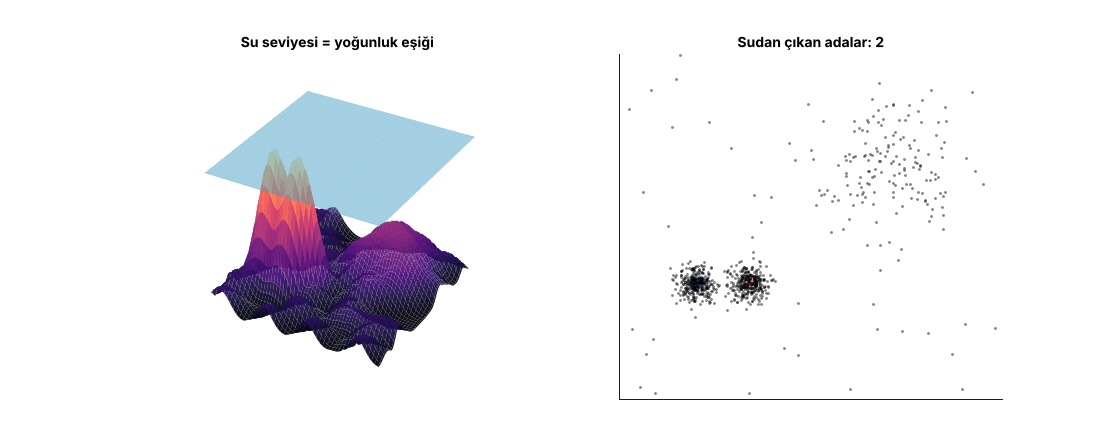

Su alçalırken ada sayısı: [2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 2, 2, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 3]


In [14]:
from scipy.ndimage import label as bilesen_bul
from scipy.stats import gaussian_kde
kde = gaussian_kde(X_y.T, bw_method=.2)
gx, gy = np.meshgrid(np.linspace(-2, 8, 170), np.linspace(-3, 6, 150))
yuz = kde(np.c_[gx.ravel(), gy.ravel()].T).reshape(gx.shape)
seviyeler = np.geomspace(yuz.max() * .9, yuz.max() * .015, 32)
ada_sayisi = []
fig = plt.figure(figsize=(14, 5.6))
a1 = fig.add_subplot(1, 2, 1, projection="3d"); a2 = fig.add_subplot(1, 2, 2)
def ciz(i):
    s = seviyeler[min(i, len(seviyeler) - 1)]
    adalar, n = bilesen_bul(yuz > s)
    if i < len(seviyeler): ada_sayisi.append(n)
    a1.clear(); a2.clear()
    yk = yuz ** .35                                     # görsel yükseklik: seyrek tepeler de görünsün diye sıkıştırılmış ölçek
    a1.plot_surface(gx, gy, yk, cmap="magma", lw=0, alpha=.95, rstride=3, cstride=3)
    a1.plot_surface(gx, gy, np.full_like(yuz, s ** .35), color="#38BDF8", alpha=.45, lw=0)
    a1.set_zlim(0, yk.max()); a1.view_init(32, -60 + i * 2); a1.set_axis_off()
    a1.set_title(f"Su seviyesi = yoğunluk eşiği", fontweight="bold")
    a2.imshow(np.where(adalar > 0, adalar, np.nan), origin="lower", extent=(-2, 8, -3, 6), cmap="tab10", vmin=1, vmax=10)
    a2.scatter(*X_y.T, s=3, c="k", alpha=.35)
    a2.set_title(f"Sudan çıkan adalar: {n}", fontweight="bold"); a2.set_xticks([]); a2.set_yticks([])
anim = FuncAnimation(fig, ciz, frames=len(seviyeler) + 5)
gif_kaydet(anim, "kavram_11_su_seviyesi", fps=4)
print("Su alçalırken ada sayısı:", ada_sayisi)

### 🤝 9.3 · Karşılıklı Erişim Mesafesi (tek cümlede)

<p align="center">
  <img src="assets/diyagram_karsilikli_erisim.svg" width="100%" alt="Karşılıklı erişim mesafesi">
</p>

HDBSCAN'in "dağ yüksekliğini" ölçmek için kullandığı hile şudur: iki nokta arasındaki mesafe, ikisinin **kendi kalabalık yarıçapından** (k'ıncı komşuya uzaklık) küçük sayılmaz. Kalabalıkta bu neredeyse hiçbir şeyi değiştirmez; ıssız yerde ise mesafeyi **şişirir**. Böylece seyrek bölgedeki tek tük noktalar iki kalabalık arasında **köprü kuramaz** (Campello ve ark., 2015).

<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10: HDBSCAN'in ağacı">
</p>

### 🌲 10.1 · Yoğunlaştırılmış Ağaç: Adaların Soy Ağacı

Su alçalırken olan biteni bir **ağaç** olarak kaydedebiliriz: dikey eksen yoğunluk (yukarısı = su yüksek = sadece en yoğunlar), dallar adalar, dalın **kalınlığı** o adadaki nokta sayısı. `min_cluster_size`'tan küçük kopmalar "ada" sayılmaz, **dökülen yaprak** (gürültü) sayılır.

İki seçim kuralı vardır:

- **EOM** (*excess of mass*, varsayılan): "En çok **kütle × ömür** biriktiren adaları seç." Genelde **büyük ve kararlı** kümeler verir.
- **Leaf** (yaprak): "Ağacın **en uçtaki** dallarını seç." Daha **çok ve küçük**, daha homojen kümeler verir.

Aşağıdaki oyuncak veride **ikiz mahalle** (birbirine çok yakın iki küçük kalabalık) ve uzakta daha büyük bir mahalle var. ARI'yi üç gerçek gruba göre hesaplıyoruz; yani "ikizleri ayrı görmek" burada doğru cevap.

Ağacı elde etmek için HDBSCAN'in özgün geliştiricilerinin `hdbscan` kütüphanesini kullanıyor, çizimi kendimiz yapıyoruz (scikit-learn'deki HDBSCAN aynı algoritmadır ama ağacı dışarı vermez).

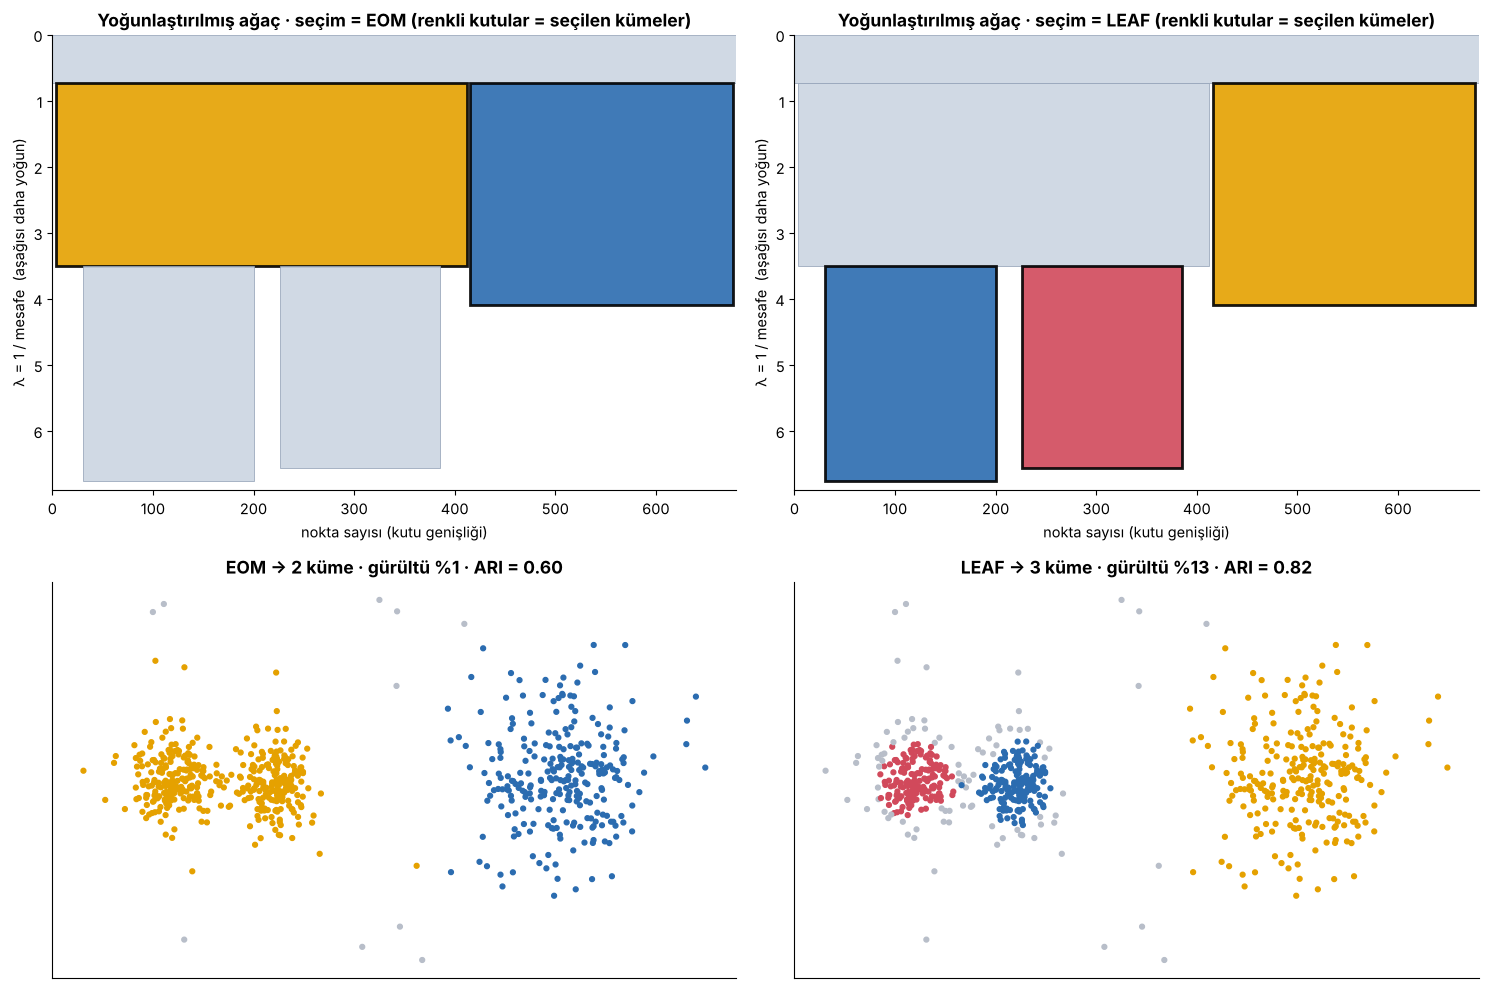

,Seçim,Küme,Gürültü %,ARI
0,EOM,2,1.5,0.598
1,LEAF,3,13.2,0.815


In [15]:
import hdbscan as hdbscan_kutuphanesi

def agac_ciz(h, ax):
    """Yoğunlaştırılmış ağacı buz sarkıtı (icicle) olarak çizer: kutu genişliği = adadaki nokta sayısı,
    dikey eksen = λ (1 / mesafe; aşağısı daha yoğun). Seçilen kümeler renkli ve kalın kenarlı."""
    df = h.condensed_tree_.to_pandas()
    secilen = list(h.condensed_tree_._select_clusters())
    kok = int(df["parent"].min())
    dogum = {kok: 0.0}; boyut = {kok: int(df.loc[df["parent"] == kok, "child_size"].sum())}
    for _, r in df[df["child_size"] > 1].iterrows():
        dogum[int(r["child"])] = r["lambda_val"]; boyut[int(r["child"])] = int(r["child_size"])
    olum = df.groupby("parent")["lambda_val"].max().to_dict()
    def yerlestir(c, x0):
        ax.add_patch(plt.Rectangle((x0, dogum[c]), boyut[c], olum.get(c, dogum[c]) - dogum[c],
                     facecolor=(KUME_RENK[secilen.index(c) % len(KUME_RENK)] if c in secilen else "#CBD5E1"),
                     edgecolor="k" if c in secilen else "#94A3B8", lw=2 if c in secilen else .6, alpha=.9))
        cocuk = df[(df["parent"] == c) & (df["child_size"] > 1)]
        bos = (boyut[c] - cocuk["child_size"].sum()) / (len(cocuk) + 1)
        x = x0 + bos
        for _, r in cocuk.iterrows():
            yerlestir(int(r["child"]), x); x += r["child_size"] + bos
    yerlestir(kok, 0)
    ax.set_xlim(0, boyut[kok]); ax.set_ylim(max(olum.values()) * 1.02, 0)
    ax.set(xlabel="nokta sayısı (kutu genişliği)", ylabel="λ = 1 / mesafe  (aşağısı daha yoğun)")

# İkiz mahalle (birbirine çok yakın iki küçük kalabalık) + uzakta daha büyük bir mahalle + gürültü
X_t, y_t = make_blobs([200, 200, 250], centers=[[-.6, 0], [.6, 0], [4, 0]], cluster_std=[.25, .25, .5], random_state=5)
X_t = np.r_[X_t, np.random.default_rng(1).uniform([-2, -2], [6, 2], (30, 2))]; y_t = np.r_[y_t, -np.ones(30, int)]
fig, ax = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"height_ratios": [1.15, 1]})
hd_satir = []
for j, yontem in enumerate(["eom", "leaf"]):
    h = hdbscan_kutuphanesi.HDBSCAN(min_cluster_size=30, cluster_selection_method=yontem).fit(X_t)
    agac_ciz(h, ax[0, j])
    ax[0, j].set_title(f"Yoğunlaştırılmış ağaç · seçim = {yontem.upper()} (renkli kutular = seçilen kümeler)")
    ax[1, j].scatter(*X_t.T, s=12, c=renkler(h.labels_)); ax[1, j].set_xticks([]); ax[1, j].set_yticks([])
    ari = adjusted_rand_score(y_t, h.labels_)
    ax[1, j].set_title(f"{yontem.upper()} → {h.labels_.max()+1} küme · gürültü %{(h.labels_<0).mean()*100:.0f} · ARI = {ari:.2f}")
    hd_satir.append({"Seçim": yontem.upper(), "Küme": h.labels_.max() + 1, "Gürültü %": round((h.labels_ < 0).mean() * 100, 1), "ARI": round(ari, 3)})
fig.tight_layout(); kaydet(fig, "kavram_12_hdbscan_agaci"); plt.show()
display(pd.DataFrame(hd_satir))

### 🗽 10.2 · New York'ta Üç Yaklaşım ve `min_cluster_size` Düğmesi

Aynı 4.000 ilanlık pencerede DBSCAN'i, HDBSCAN-EOM'u ve HDBSCAN-yaprak'ı karşılaştırıyoruz. Ardından animasyonda `min_cluster_size`'ı 10'dan 200'e büyütüyoruz: "bir odak en az kaç ilandan oluşmalı?"

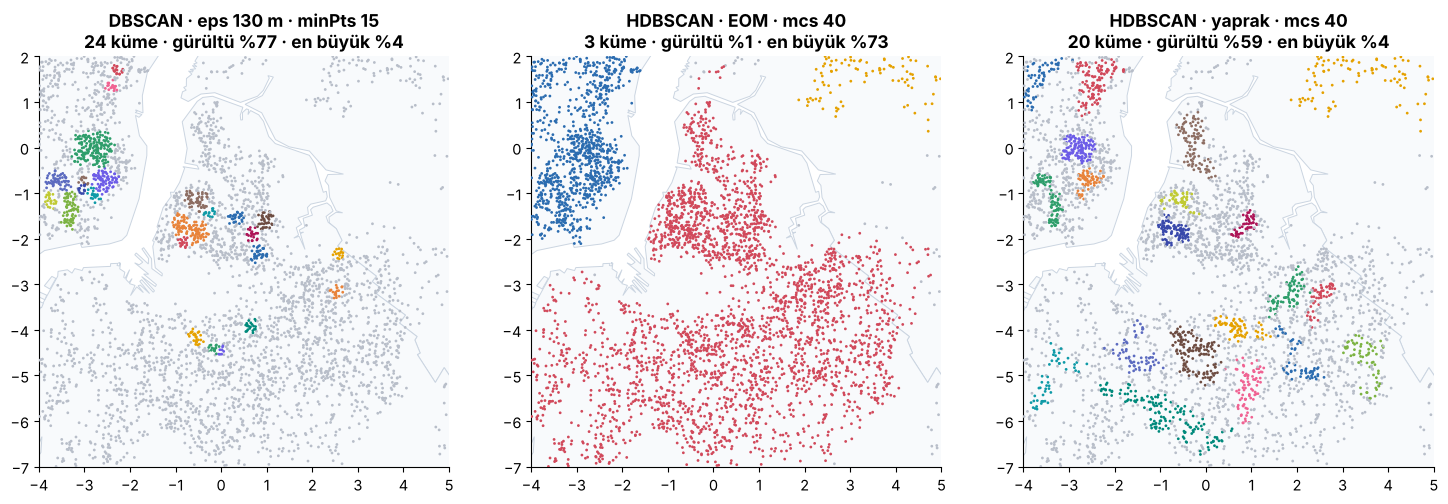

,Yöntem,Odak sayısı,Gürültü %,En büyük odak %,DBCV
0,DBSCAN · eps 130 m · minPts 15,24.0,77.4,4.4,0.012
1,HDBSCAN · EOM · mcs 40,3.0,1.1,72.8,-0.002
2,HDBSCAN · yaprak · mcs 40,20.0,59.1,3.6,0.147


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6)); uc = []
for a, (ad, m) in zip(ax, [("DBSCAN · eps 130 m · minPts 15", DBSCAN(eps=.13, min_samples=15)),
                          ("HDBSCAN · EOM · mcs 40", HDBSCAN(min_cluster_size=40, min_samples=15, copy=True)),
                          ("HDBSCAN · yaprak · mcs 40", HDBSCAN(min_cluster_size=40, min_samples=15, cluster_selection_method="leaf", copy=True))]):
    et = m.fit_predict(Zp); oz = kume_ozeti(et)
    nyc_haritasi(a, PROJ, dolgu="#F8FAFC", kenar="#CBD5E1")
    a.scatter(*Zp.T, s=4, c=renkler(et), lw=0, zorder=3); a.set_xlim(-4, 5); a.set_ylim(-7, 2)
    a.set_title(f"{ad}\n{oz['Odak sayısı']} küme · gürültü %{oz['Gürültü %']:.0f} · en büyük %{oz['En büyük odak %']:.0f}")
    uc.append({"Yöntem": ad, **{k: round(float(v), 1) for k, v in oz.items()}, "DBCV": round(dbcv_skoru(Zp, et), 3)})
kaydet(fig, "kavram_13_nyc_uc_yontem"); plt.show()
pd.DataFrame(uc).to_csv(REP_DIR / "kavram_nyc_uc_yontem.csv", index=False); display(pd.DataFrame(uc))

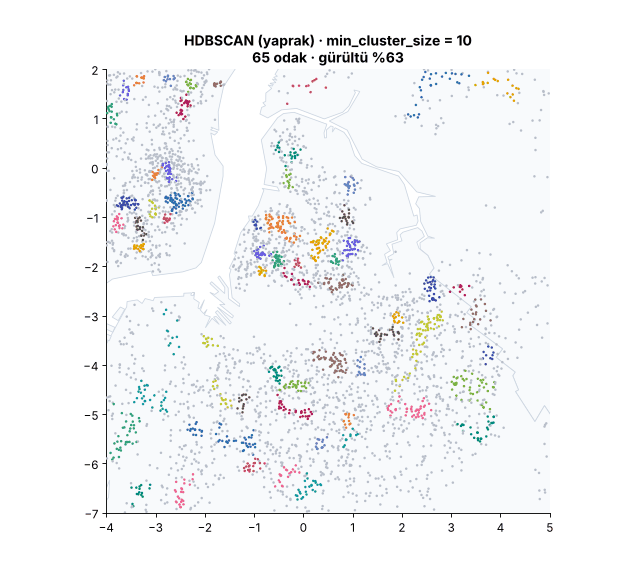

In [17]:
MCS = [10, 15, 20, 30, 40, 60, 80, 110, 150, 200]
fig, ax = plt.subplots(figsize=(8, 7.2))
def ciz(i):
    m = MCS[min(i, len(MCS) - 1)]
    et = HDBSCAN(min_cluster_size=m, min_samples=10, cluster_selection_method="leaf", copy=True).fit_predict(Zp)
    oz = kume_ozeti(et); ax.clear()
    nyc_haritasi(ax, PROJ, dolgu="#F8FAFC", kenar="#CBD5E1")
    ax.scatter(*Zp.T, s=5, c=renkler(et), lw=0, zorder=3); ax.set_xlim(-4, 5); ax.set_ylim(-7, 2)
    ax.set_title(f"HDBSCAN (yaprak) · min_cluster_size = {m}\n{oz['Odak sayısı']} odak · gürültü %{oz['Gürültü %']:.0f}")
anim = FuncAnimation(fig, ciz, frames=len(MCS) + 3)
gif_kaydet(anim, "kavram_14_mcs_supurme", fps=2)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

- **EOM**, Manhattan–Brooklyn halısını çoğu zaman **tek dev küme** olarak görür: çünkü su alçalırken o halı çok uzun süre "tek parça" kalır, yani gerçekten **kararlıdır**. Bu bir hata değil, sorulan sorunun cevabıdır.
- **Yaprak** seçimi "halının içindeki daha parlak benekleri" verir: daha çok, daha küçük **odaklar**, ama daha fazla gürültü.
- Hangisinin "doğru" olduğunu algoritma değil, **iş sorusu** belirler: "Şehrin genel Airbnb bölgesi neresi?" sorusu için EOM; "Denetim ekiplerini hangi sokak kümelerine gönderelim?" sorusu için yaprak daha uygundur. Proje notebook'unda bu kararı **önceden yazılmış kurallarla** vereceğiz.

</td></tr></table>

### 🏔️ 10.3 · OPTICS: Vadiler ve Tepeler

HDBSCAN'in yakın akrabası **OPTICS** (Ankerst ve ark., 1999) noktaları "kalabalıktan kalabalığa yürüyecek" şekilde sıralar ve her adımda **erişim mesafesini** çizer. Bu **erişilebilirlik grafiğinde** kümeler **vadi**, aralarındaki boşluklar **tepe** olarak görünür. Grafiği yatay bir çizgiyle kesmek, o yükseklikteki eps ile DBSCAN çalıştırmaya denktir.

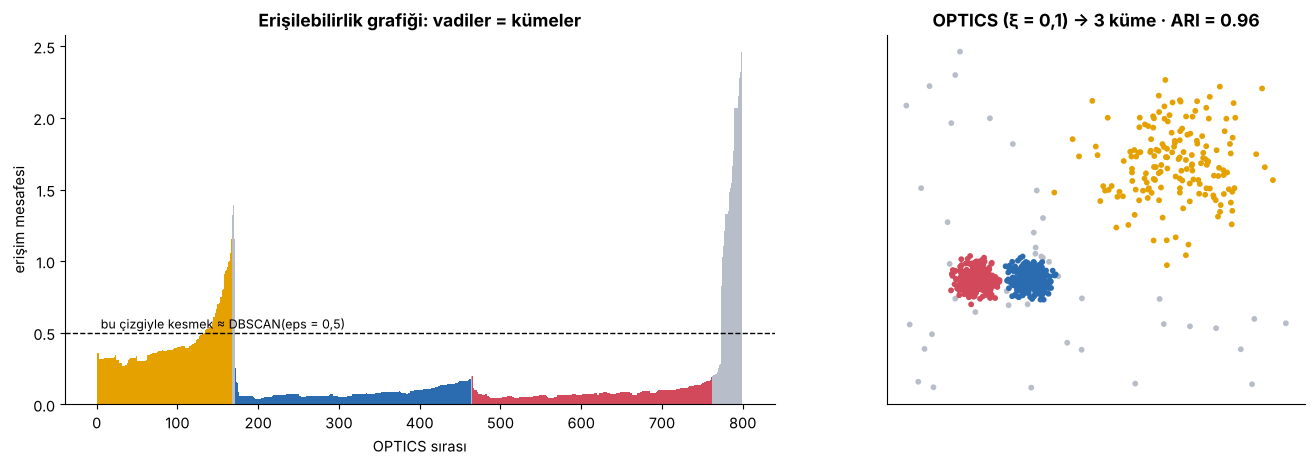

In [18]:
op = OPTICS(min_samples=10, xi=.1, min_cluster_size=60).fit(X_y)
eris = op.reachability_[op.ordering_]; et_sirali = op.labels_[op.ordering_]
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
ax[0].bar(np.arange(len(eris)), np.where(np.isinf(eris), np.nan, eris), width=1, color=renkler(et_sirali))
ax[0].axhline(.5, ls="--", c="k", lw=1); ax[0].text(5, .53, "bu çizgiyle kesmek ≈ DBSCAN(eps = 0,5)", fontsize=9)
ax[0].set(xlabel="OPTICS sırası", ylabel="erişim mesafesi", title="Erişilebilirlik grafiği: vadiler = kümeler")
ax[1].scatter(*X_y.T, s=10, c=renkler(op.labels_)); ax[1].set_xticks([]); ax[1].set_yticks([])
ax[1].set_title(f"OPTICS (ξ = 0,1) → {op.labels_.max()+1} küme · ARI = {adjusted_rand_score(y_y, op.labels_):.2f}")
kaydet(fig, "kavram_15_optics"); plt.show()

<p align="center">
  <img src="assets/diyagram_dbscan_hdbscan.svg" width="100%" alt="DBSCAN ve HDBSCAN karşılaştırma tablosu">
</p>

<a id="p11"></a>

<p align="center">
  <img src="assets/kavram_11.svg" width="100%" alt="Bölüm 11: Nasıl ölçeriz?">
</p>

### 📐 11.1 · Etiket Yokken Kalite

<p align="center">
  <img src="assets/diyagram_olcutler.svg" width="100%" alt="Kalite ölçütleri">
</p>

Gün 55'te öğrendiğimiz **silüet** "noktam kendi kümesine, komşu kümeden daha mı yakın?" diye sorar; **yuvarlak ve ayrık** kümeleri ödüllendirir. Hilal gibi uzun kümelerde bir hilalin iki ucu birbirinden çok uzaktır; silüet bunu "kötü küme" sanır.

**DBCV** (*Density-Based Clustering Validation*; Moulavi ve ark., 2014) ise şunu sorar: "Kümenin **içindeki en seyrek geçit**, kümeyi komşusundan ayıran **en dar boşluktan** daha mı yoğun?" Bu soru şekilden bağımsızdır. −1 ile +1 arasında değer alır; gürültü noktaları paydada sayılır, yani **çok fazla gürültü** de cezalandırılır.

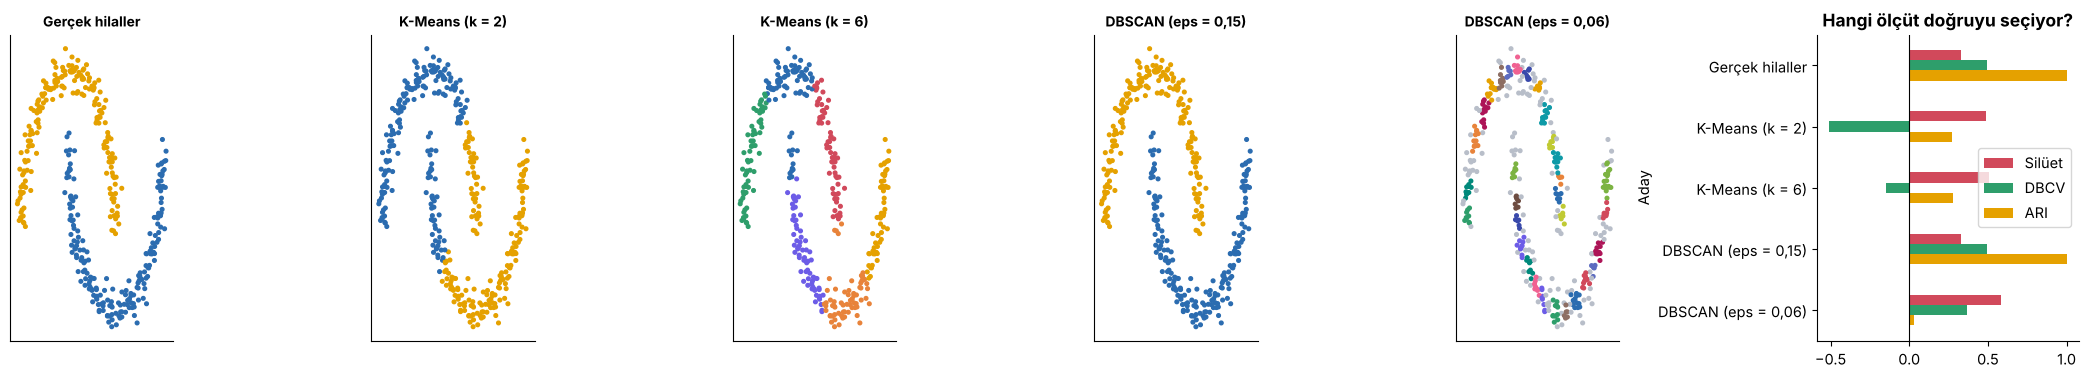

,Silüet,DBCV,Gürültü %,ARI
Aday,,,,
Gerçek hilaller,0.330,0.495,0.00,1.000
K-Means (k = 2),0.489,-0.511,0.00,0.274
K-Means (k = 6),0.504,-0.149,0.00,0.278
"DBSCAN (eps = 0,15)",0.330,0.495,0.00,1.000
"DBSCAN (eps = 0,06)",0.585,0.365,30.25,0.031


In [19]:
X_m, y_m = make_moons(400, noise=.06, random_state=0)
adaylar = {"Gerçek hilaller": y_m, "K-Means (k = 2)": KMeans(2, n_init=10, random_state=0).fit_predict(X_m),
           "K-Means (k = 6)": KMeans(6, n_init=10, random_state=0).fit_predict(X_m),
           "DBSCAN (eps = 0,15)": DBSCAN(eps=.15, min_samples=5).fit_predict(X_m),
           "DBSCAN (eps = 0,06)": DBSCAN(eps=.06, min_samples=5).fit_predict(X_m)}
olc = []
for ad, et in adaylar.items():
    m = et >= 0
    olc.append({"Aday": ad, "Silüet": silhouette_score(X_m[m], et[m]) if len(set(et[m])) > 1 else np.nan,
                "DBCV": dbcv_skoru(X_m, et), "Gürültü %": 100 * (et < 0).mean(), "ARI": adjusted_rand_score(y_m, et)})
olc = pd.DataFrame(olc).set_index("Aday").round(3)
olc.to_csv(REP_DIR / "kavram_olcut_karsilastirma.csv")
fig, ax = plt.subplots(1, 6, figsize=(21, 3.9), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1, 1.6]})
for a, (ad, et) in zip(ax, adaylar.items()):
    a.scatter(*X_m.T, s=7, c=renkler(et)); a.set_xticks([]); a.set_yticks([]); a.set_title(ad, fontsize=10)
olc[["Silüet", "DBCV", "ARI"]].plot.barh(ax=ax[5], color=[RENK["pembe"], RENK["yesil"], RENK["altin"]])
ax[5].axvline(0, c="k", lw=.8); ax[5].set_title("Hangi ölçüt doğruyu seçiyor?"); ax[5].invert_yaxis()
fig.tight_layout(); kaydet(fig, "kavram_16_siluet_tuzagi"); plt.show()
display(olc)

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

**Silüet tuzağı:** Silüet, hilalleri yanlış kesen **K-Means'e** gerçek hilallerden **daha yüksek** puan veriyor. DBCV ise gerçek yapıyı (ve onu bulan DBSCAN'i) en üste koyuyor ve fazla küçük eps'in ürettiği gürültü yığınını cezalandırıyor. Yoğunluk tabanlı kümelemede ana ölçüt olarak **DBCV**'yi kullanacağız; silüeti, gürültü oranını ve kararlılığı **yardımcı** ölçüt olarak raporlayacağız.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/kavram_12.svg" width="100%" alt="Bölüm 12: Yeni ilan">
</p>

### 🆕 12.1 · DBSCAN'de `predict()` Yok: Ne Yapacağız?

<p align="center">
  <img src="assets/diyagram_yeni_nokta.svg" width="100%" alt="Yeni ilanın odağa atanması">
</p>

K-Means'te yeni gelen nokta en yakın merkeze gider. DBSCAN'de merkez yoktur; scikit-learn bu yüzden `predict()` sunmaz. Mantıklı ve **sızıntısız** kural şudur: yeni ilan, eğitimdeki **en yakın çekirdek ilanın** fener ışığındaysa (≤ eps) o kümeye katılır, değilse gürültüdür. Bu, DBSCAN'in sınır noktalarına uyguladığı kuralın aynısıdır ve eğitimde bulunan kümeleri **değiştirmez**.

Yardımcı modüldeki `YogunlukAtayici` bu kuralı paketler. HDBSCAN için aynı fikrin daha incelikli bir sürümü vardır: özgün `hdbscan` kütüphanesinin **`approximate_predict`** yöntemi, yeni noktayı eğitimde kurulan yoğunluk ağacına yerleştirir (McInnes ve ark., 2017); proje notebook'unda final model için onu kullanıyoruz. Şimdi pencereyi **%80 eğitim / %20 yeni** olarak ayırıp deneyelim; kontrol olarak tüm ilanlarla sıfırdan kurulan modelin aynı ilanlara ne dediğine bakalım.

Yeni ilan: 825 | odağa atanan: 143 | gürültü: 682
Yeni ilanlarda ARI(atama, sıfırdan kurulan model) = 0.772
'Odakta mı / gürültü mü?' kararında uyum: % 93.5


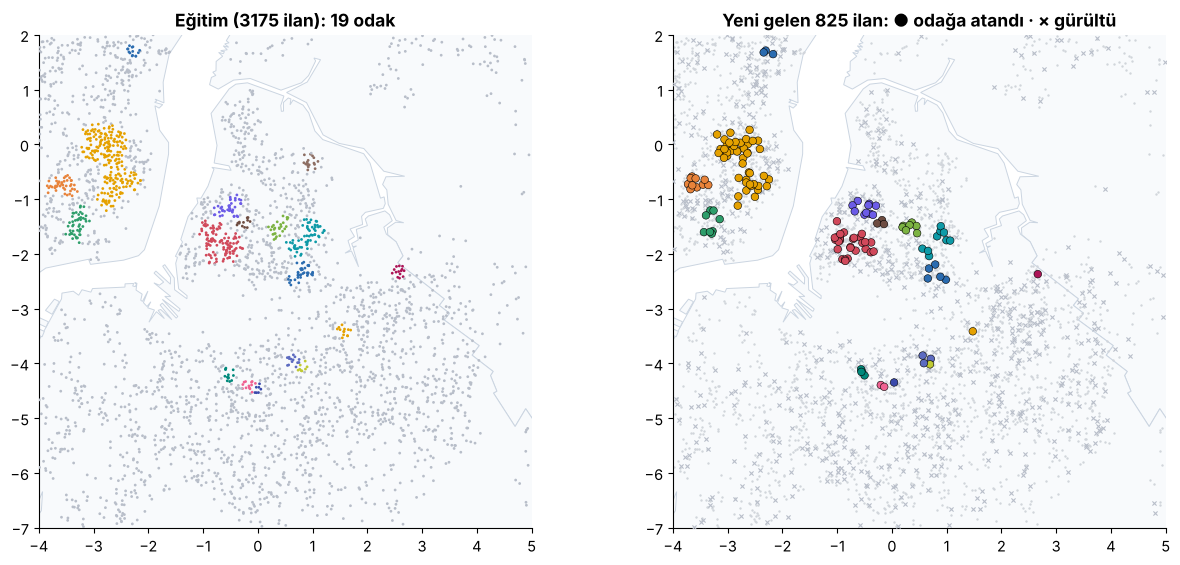

In [20]:
rng = np.random.default_rng(RANDOM_STATE); yeni_mi = rng.random(len(Zp)) < .2
# Eğitimde ilanların %80'i var: aynı "kalabalık" tanımı için minPts de %80'e iner (15 × 0,8 = 12)
atayici = YogunlukAtayici(DBSCAN(eps=.13, min_samples=12)).fit(Zp[~yeni_mi])
et_yeni = atayici.predict(Zp[yeni_mi])
et_hepsi = DBSCAN(eps=.13, min_samples=15).fit_predict(Zp)         # yalnızca kontrol amaçlı
print(f"Yeni ilan: {yeni_mi.sum()} | odağa atanan: {(et_yeni >= 0).sum()} | gürültü: {(et_yeni < 0).sum()}")
print("Yeni ilanlarda ARI(atama, sıfırdan kurulan model) =", round(adjusted_rand_score(et_hepsi[yeni_mi], et_yeni), 3))
print("'Odakta mı / gürültü mü?' kararında uyum: %", round(100 * ((et_yeni < 0) == (et_hepsi[yeni_mi] < 0)).mean(), 1))

fig, ax = plt.subplots(1, 2, figsize=(15, 6.4))
for a in ax: nyc_haritasi(a, PROJ, dolgu="#F8FAFC", kenar="#CBD5E1"); a.set_xlim(-4, 5); a.set_ylim(-7, 2)
ax[0].scatter(*Zp[~yeni_mi].T, s=4, c=renkler(atayici.labels_), lw=0, zorder=3)
ax[0].set_title(f"Eğitim ({(~yeni_mi).sum()} ilan): {atayici.labels_.max()+1} odak")
ax[1].scatter(*Zp[~yeni_mi].T, s=3, c="#D1D5DB", lw=0, zorder=2)
ax[1].scatter(*Zp[yeni_mi][et_yeni < 0].T, s=9, c=GURULTU, marker="x", lw=.8, zorder=3)
ax[1].scatter(*Zp[yeni_mi][et_yeni >= 0].T, s=30, c=renkler(et_yeni[et_yeni >= 0]), edgecolor="k", lw=.4, zorder=4)
ax[1].set_title(f"Yeni gelen {yeni_mi.sum()} ilan: ● odağa atandı · × gürültü")
kaydet(fig, "kavram_17_yeni_ilan"); plt.show()

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Yeni ilanların büyük çoğunluğu, tüm veriyle sıfırdan kurulsaydı alacakları kararı alıyor ("odakta mı?" uyumu ve ARI'ye bakın). Eğitimde verinin yalnızca %80'i olduğu için **minPts'i de aynı oranda** küçülttük; aksi halde eğitim modeli daha "seyrek" bir şehir görür ve gereğinden fazla gürültü üretirdi. Bu küçük ayrıntı, yoğunluk yöntemlerinde **örneklem büyüklüğü ile minPts'in birlikte düşünülmesi** gerektiğini hatırlatıyor. Fark eden az sayıda ilan, kendi varlığıyla bir bölgeyi **kalabalık eşiğinin üstüne çıkaracak** olanlardır: sıfırdan kurulan model onları görür, bizim atayıcımız eğitimi değiştirmediği için görmez. Bu, test bilgisini modele **sızdırmamanın** bilinçli bedelidir.

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/kavram_13.svg" width="100%" alt="Bölüm 13: Özet">
</p>

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

| # | Fikir | Tek cümle |
|:-:|:--|:--|
| 1 | Yoğunluk tabanlı kümeleme | "Yanında yeterince komşu olan nokta kalabalıktır; birbirine değen kalabalıklar tek kümedir." |
| 2 | eps & minPts | Fenerin yarıçapı ve kalabalık sayılmak için gereken kişi sayısı |
| 3 | Üç nokta türü | ⭐ çekirdek yayar · 🔆 sınır katılır · ✖ gürültü dışarıda kalır (−1) |
| 4 | Küme sayısı | Siz söylemezsiniz; veri söyler |
| 5 | k-mesafe dirseği | eps için iyi bir **başlangıç**, kesin kural değil |
| 6 | Birim | Mesafe birimini anlamlı seçin (şehirde km; derece ve z-skor feneri elips yapar) |
| 7 | DBSCAN'in zaafı | Tek eps, farklı yoğunluklara aynı anda uymaz |
| 8 | HDBSCAN | Tüm yoğunluk seviyelerini tarar, en kararlı adaları seçer (EOM: büyük, yaprak: ince taneli) |
| 9 | Ölçüt | Silüet hilallerde yanıltır; yoğunluk kümeleri için **DBCV** |
| 10 | Yeni nokta | En yakın çekirdeğin ışığındaysa katıl, değilse gürültü |

### 📝 Mini Quiz

<details><summary><b>1) minPts = 5 iken fenerinde 3 kişi olan, ama bir çekirdeğin 0,2 km yakınında duran bir ilan (eps = 0,25 km) hangi türdür?</b></summary>

**Sınır** noktası: kendisi çekirdek değil ama bir çekirdeğin ışığında. Kümeye katılır, ama kümeyi yaymaz.
</details>

<details><summary><b>2) eps'i çok büyütürseniz ne olur?</b></summary>

Kalabalıklar birbirine değer ve **birleşir**; sonunda neredeyse tüm veri tek bir dev kümeye dönüşür.
</details>

<details><summary><b>3) Konum verisini derece cinsinden bırakıp eps = 0,002 seçmenin sakıncası nedir?</b></summary>

New York'ta 1° boylam ≈ 84 km, 1° enlem ≈ 111 km olduğu için fener bir **elips** olur; doğu-batı ve kuzey-güney yönleri eşit muamele görmez. Kilometreye çevirmek bunu düzeltir ve eps'e fiziksel anlam kazandırır.
</details>

<details><summary><b>4) Silüet ve DBCV aynı kümelemeye farklı not verirse hangisine güvenirsiniz?</b></summary>

Şekiller yuvarlak değilse ve gürültü varsa **DBCV**'ye. Silüet merkez ve yuvarlaklık varsayar; DBCV ise kümenin içindeki yoğunluğu, kümeler arasındaki boşlukla karşılaştırır.
</details>

<details><summary><b>5) HDBSCAN'de EOM ile yaprak seçimi arasındaki fark nedir?</b></summary>

EOM en çok "kütle × ömür" biriktiren, genelde **büyük ve kararlı** kümeleri seçer; yaprak seçimi ağacın uçlarındaki **küçük ve homojen** kümeleri seçer.
</details>

### 🏋️ Ödevler

1. **Kendi sokağınız:** 5.1'deki 12 ilanın koordinatlarını değiştirin; K ve L'yi kümeye katmak için eps'in en az ne olması gerektiğini elle hesaplayın, sonra kodla doğrulayın.
2. **Haversine:** 6. duraktaki pencereyi derece cinsinden bırakıp `DBSCAN(metric="haversine", algorithm="ball_tree")` ile çalıştırın (eps'i radyana çevirmeyi unutmayın: `eps_km / 6371`). Sonuçlar kilometre ızgarasıyla ne kadar örtüşüyor (ARI)?
3. **Staten Island:** Yalnızca Staten Island ilanlarıyla k-mesafe grafiği çizin. Dirsekteki eps, Manhattan'dakinden kaç kat büyük? Bu size farklı yoğunluklar hakkında ne söylüyor?
4. **Ölçüt avcısı:** 11. duraktaki tabloya `davies_bouldin_score` ekleyin. Silüete mi yoksa DBCV'ye mi benziyor?

### 📚 KAYNAKÇA

Metindeki dolaylı atıflar, kullanıcı protokolüne uygun olarak **(B, APA 7, A'dan aktarma)** biçiminde verilmiştir. Örneğin DBSCAN'in özgün tanımı ve k-mesafe sezgisi Ester ve ark. (1996)'ya aittir; bu notebook'ta bu bilgi Schubert ve ark. (2017)'nin yeniden değerlendirmesinden aktarılmıştır: *(Ester ve ark., 1996; Schubert ve ark., 2017'den aktarma)*. minPts için "2 × boyut" önerisi de Sander ve ark. (1998)'e dayanır ve yine Schubert ve ark. (2017) üzerinden aktarılmıştır.

- Ankerst, M., Breunig, M. M., Kriegel, H.-P., & Sander, J. (1999). OPTICS: Ordering points to identify the clustering structure. *ACM SIGMOD Record, 28*(2), 49–60. https://doi.org/10.1145/304181.304187
- Bhattacharjee, P., & Mitra, P. (2021). A survey of density based clustering algorithms. *Frontiers of Computer Science, 15*(1), Article 151308. https://doi.org/10.1007/s11704-019-9059-3
- Bushra, A. A., & Yi, G. (2021). Comparative analysis review of pioneering DBSCAN and successive density-based clustering algorithms. *IEEE Access, 9*, 87918–87935. https://doi.org/10.1109/ACCESS.2021.3089036
- Campello, R. J. G. B., Moulavi, D., & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. In J. Pei, V. S. Tseng, L. Cao, H. Motoda, & G. Xu (Eds.), *Advances in knowledge discovery and data mining (PAKDD 2013)* (Lecture Notes in Computer Science, Vol. 7819, pp. 160–172). Springer. https://doi.org/10.1007/978-3-642-37456-2_14
- Campello, R. J. G. B., Moulavi, D., Zimek, A., & Sander, J. (2015). Hierarchical density estimates for data clustering, visualization, and outlier detection. *ACM Transactions on Knowledge Discovery from Data, 10*(1), Article 5. https://doi.org/10.1145/2733381
- Dgomonov. (2019). *New York City Airbnb open data* [Data set]. Kaggle. https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. In *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)* (pp. 226–231). AAAI Press.
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- McInnes, L., Healy, J., & Astels, S. (2017). hdbscan: Hierarchical density based clustering. *Journal of Open Source Software, 2*(11), 205. https://doi.org/10.21105/joss.00205
- Moulavi, D., Jaskowiak, P. A., Campello, R. J. G. B., Zimek, A., & Sander, J. (2014). Density-based clustering validation. In *Proceedings of the 2014 SIAM International Conference on Data Mining* (pp. 839–847). SIAM. https://doi.org/10.1137/1.9781611973440.96
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (1998). Density-based clustering in spatial databases: The algorithm GDBSCAN and its applications. *Data Mining and Knowledge Discovery, 2*(2), 169–194. https://doi.org/10.1023/A:1009745219419
- Satopää, V., Albrecht, J., Irwin, D., & Raghavan, B. (2011). Finding a "kneedle" in a haystack: Detecting knee points in system behavior. In *2011 31st International Conference on Distributed Computing Systems Workshops* (pp. 166–171). IEEE. https://doi.org/10.1109/ICDCSW.2011.20
- Schubert, E., Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (2017). DBSCAN revisited, revisited: Why and how you should (still) use DBSCAN. *ACM Transactions on Database Systems, 42*(3), Article 19. https://doi.org/10.1145/3068335